# Setup

In [2]:
%load_ext autoreload
%autoreload 2

from IPython.display import display
import os
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import matplotlib.colors as mcolors
import matplotlib.markers as mmarkers
import seaborn as sns
import scipy

from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils

import main_analysis as ma
import paths

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Avenir'

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/postvss25'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
KONKLE_LOCALIZER_DIR = paths.KONKLE_LOCALIZER_DIR
KANWISHER_LOCALIZER_DIR = paths.KANWISHER_LOCALIZER_DIR


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# Utils

def get_shades(hex_color, n=5, lighten_limit=0.25, darken_limit=0.75):
    """
    Generate n shades around a base hex_color.
    Base sits in the middle, lighter tints above, darker shades below.
    
    lighten_limit: how much lighter the lightest color can get (0-1)
    darken_limit: how much darker the darkest color can get (0-1)
    """
    rgb = np.array(mcolors.to_rgb(hex_color))
    colors = []
    mid = (n - 1) / 2
    
    for i in range(n):
        factor = (i - mid) / mid  # ranges -1..1
        if factor < 0:
            # lighter: move towards white but limited
            new_rgb = rgb + (1 - rgb) * (-factor * lighten_limit)
        else:
            # darker: move towards black but limited
            new_rgb = rgb * (1 - factor * darken_limit)
        colors.append(np.clip(new_rgb, 0, 1))
    return colors

# Fig 2

In [2]:
# Settings

plot_dir = f'{PLOTS_DIR}/fig2'
os.makedirs(plot_dir, exist_ok=True)

frois = ['FFA', 'PPA', 'EBA']

ordered_categories = ['faces', 'scenes', 'bodies', 'objects']

category_colors = {
    'faces': '#f09678',
    'scenes': '#a6d2e5',
    'bodies': '#a7d6a1',
    'objects': '#808080',
}

ordered_colors = [category_colors[cat] for cat in ordered_categories]

MODEL_PLOTTING_NAMES = {
    # # AlexNets
    'alexnetimagenet1kv1': 'AlexNet ImageNet-1K',
    'alexnetipclref01': 'AlexNet IPCL',
    'alexnetbarlowtwins': 'AlexNet Barlow-Twins',
    # # VGGs
    'vgg16imagenet1kv1': 'VGG-16 ImageNet-1K',
    # # ResNet-18s
    'resnet18imagenet1kv1': 'ResNet-18 ImageNet-1K',
    'resnet18tdannsupervisedlw10': 'ResNet-18 TDANN-Supervised',
    'resnet18tdannsimclrlw1': 'ResNet-18 TDANN-SimCLR',
    # # ResNet-50s
    'resnet50imagenet1kv2': 'ResNet-50 ImageNet-1K',
    'resnet50openaiclip': 'ResNet-50 CLIP',
    'resnet50simclr': 'ResNet-50 SimCLR',
    'resnet50robustl2eps3': 'ResNet-50 Robust',
    'resnet50sin': 'ResNet-50 Shape-Biased',
    'resnet50ecoset': 'ResNet-50 EcoSet',
    'resnet50faceobfuscation': 'ResNet-50 Face-Deprived',
    'resnet50toponettau30': 'ResNet-50 TopoNet',
    'resnet50cesslbarlowtop': 'ResNet-50 CE-SSL',
    'resnet50blurstrong': 'ResNet-50 Strong-Blur',
    # # ResNet-101s
    'resnet101imagenet1kv1': 'ResNet-101 ImageNet-1K',
    'resnet101openaiclip': 'ResNet-101 CLIP',
    # # # BagNets
    'bagnet33': 'BagNet-33 ImageNet-1K',
    # # # CORNets
    'cornets': 'CORNet-S',
    'cornetz': 'CORNet-Z',
    # # # ConvNeXt
    'convnexttinyimagenet1kv1': 'ConvNeXt-T ImageNet-1K',
    # # # ViTs
    # # # ViT-B/32
    'vitb32imagenet1kv1': 'ViT-B/32 ImageNet-1K',
    'vitb32openaiclip': 'ViT-B/32 CLIP',
    'vitb32dreamsimopenclip': 'ViT-B/32 DreamSim',
    # # # ViT-B/16
    'vitb16imagenet21k': 'ViT-B/16 ImageNet-21K',
    'vitb16openaiclip': 'ViT-B/16 CLIP',
    'vitb16siglip2res224': 'ViT-B/16 SigLIP2',
    'vitb16eva028bs8bb131k': 'ViT-B/16 EVA-02',
    'vitb16synclr': 'ViT-B/16 SynCLR',
    # # # ViT-B/14
    'vitb14dinov2': 'ViT-B/14 DINOv2',
    'vitb14dinov2reg': 'ViT-B/14 DINOv2-Reg',
    # # # ViT-L/14
    'vitl14openaiclip': 'ViT-L/14 CLIP',
    'vitl14kosmos2': 'ViT-L/14 Kosmos-2',
}

## Stats: GrillSpector -> Konkle localizer

In [10]:
model_names = ma.get_model_names()

tthreshold = 7
model_localizer = 'grillspector'
model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR
indepedent_localizer = 'konkle'
indepedent_localizer_dir = KONKLE_LOCALIZER_DIR

fig2_stats_csv = f'{plot_dir}/fig2_stats_localizer_{model_localizer}_validate_{indepedent_localizer}.csv'

for froi in frois:
    pref_category = None
    if froi == 'FFA':
        pref_category = 'faces'
    elif froi == 'PPA':
        pref_category = 'scenes'
    elif froi == 'EBA':
        pref_category = 'bodies'
    for midx, model_name in enumerate(model_names):
        model = ma.get_model(model_name)
        model.eval()
        print(f'Processing model: {model.name}, froi: {froi}')
        # Get number of units localized in the froi
        froi_mask = localizer.get_froi_mask(
            model_localizer_dir, model_localizer, MODELS_DIR,
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            froi, tthreshold
        )
        num_units = froi_mask.sum().item()
        # FBSO
        independent_acts = model_utils.get_dataset_activations(
            MODELS_DIR, indepedent_localizer_dir, \
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            dataset='localizer', localizer_type=indepedent_localizer, \
            froi=froi, tthreshold=tthreshold, \
            froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir
        )
        independent_acts_univariate = {k: v.mean(axis=-1) for k, v in independent_acts.items()}

        # Prepare data for plotting with z-scoring
        categories = list(independent_acts_univariate.keys())

        # Get all activations and compute overall mean and std for z-scoring
        all_vals = torch.cat([independent_acts_univariate[cat] for cat in categories])
        overall_mean = all_vals.mean().cpu().numpy()
        overall_std = all_vals.std().cpu().numpy()

        # Z-score the activations
        independent_acts_zscored = {
            cat: (independent_acts_univariate[cat].cpu().numpy() - overall_mean) / overall_std
            for cat in categories
        }
        # Get the preferred category for the froi
        pref_category_zscored = independent_acts_zscored[pref_category]
        # Get the other categories
        other_categories_zscored = {
            cat: independent_acts_zscored[cat] for cat in categories if cat != pref_category
        }
        # Loop over the non-preferred categories and conduct unpaired welch's t-test
        for cat, acts in other_categories_zscored.items():
            # Perform unpaired Welch's t-test
            t_stat, p_value = scipy.stats.ttest_ind(
                pref_category_zscored, acts, equal_var=False
            )
            print(f'Unpaired Welch\'s t-test between {pref_category} and {cat}: t-statistic={t_stat}, p-value={p_value}')
            # Create a DataFrame for the stats
            stats_df = pd.DataFrame({
                'model': [model_name],
                'froi': [froi],
                'num_units': [num_units],
                'pref_category': [pref_category],
                'non_pref_category': [cat],
                't_statistic': [t_stat],
                'p_value': [p_value]
            })
            # Save the stats to a CSV file
            if not os.path.exists(fig2_stats_csv):
                stats_df.to_csv(fig2_stats_csv, index=False)
            else:
                stats_df.to_csv(fig2_stats_csv, mode='a', header=False, index=False)

Processing model: alexnetimagenet1kv1, froi: FFA
Unpaired Welch's t-test between faces and bodies: t-statistic=8.782687072920837, p-value=5.560387862691273e-10
Unpaired Welch's t-test between faces and scenes: t-statistic=9.842489579469627, p-value=4.94171734320853e-11
Unpaired Welch's t-test between faces and objects: t-statistic=9.513541974685856, p-value=1.545885965876941e-10


Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


Processing model: alexnetipclref01, froi: FFA
Unpaired Welch's t-test between faces and bodies: t-statistic=9.125097546889975, p-value=8.326208738849573e-13
Unpaired Welch's t-test between faces and scenes: t-statistic=12.059521649450101, p-value=5.3953431921099317e-17
Unpaired Welch's t-test between faces and objects: t-statistic=14.243603387491286, p-value=8.024467061227552e-18
Processing model: alexnetbarlowtwins, froi: FFA
Unpaired Welch's t-test between faces and bodies: t-statistic=10.723705966168358, p-value=2.1861839611212364e-15
Unpaired Welch's t-test between faces and scenes: t-statistic=18.140927630442665, p-value=6.442936605892916e-25
Unpaired Welch's t-test between faces and objects: t-statistic=16.048877497585288, p-value=1.4435230905749893e-19
Processing model: vgg16imagenet1kv1, froi: FFA
Unpaired Welch's t-test between faces and bodies: t-statistic=12.293269872586343, p-value=5.030470925478978e-14
Unpaired Welch's t-test between faces and scenes: t-statistic=13.634056

/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Processing model: resnet50toponettau30, froi: FFA
Unpaired Welch's t-test between faces and bodies: t-statistic=12.631844639810941, p-value=3.9757951656368847e-14
Unpaired Welch's t-test between faces and scenes: t-statistic=14.837365954443547, p-value=1.9734857713066803e-15
Unpaired Welch's t-test between faces and objects: t-statistic=13.844698956708225, p-value=1.6357122435643553e-14
Processing model: resnet50cesslbarlowtop, froi: FFA
Unpaired Welch's t-test between faces and bodies: t-statistic=14.256182759043984, p-value=1.6031850743782517e-20
Unpaired Welch's t-test between faces and scenes: t-statistic=18.325193929135825, p-value=6.6172226155711884e-24
Unpaired Welch's t-test between faces and objects: t-statistic=19.522704296430966, p-value=2.8799413028815262e-21
Processing model: resnet50blurstrong, froi: FFA
Unpaired Welch's t-test between faces and bodies: t-statistic=13.545881680778528, p-value=2.6621539503253403e-18
Unpaired Welch's t-test between faces and scenes: t-stati

...

Processing model: vitb32dreamsimopenclip, froi: EBA
Unpaired Welch's t-test between bodies and faces: t-statistic=11.633484197385403, p-value=5.686542402022528e-16
Unpaired Welch's t-test between bodies and scenes: t-statistic=12.313785928900941, p-value=6.839032764455635e-17
Unpaired Welch's t-test between bodies and objects: t-statistic=6.783741789108215, p-value=2.0843887396096907e-08
Processing model: vitb16imagenet21k, froi: EBA
Unpaired Welch's t-test between bodies and faces: t-statistic=8.71661636124961, p-value=1.482146502841966e-11
Unpaired Welch's t-test between bodies and scenes: t-statistic=8.155566891031174, p-value=3.7803071020227316e-10
Unpaired Welch's t-test between bodies and objects: t-statistic=6.249899477686203, p-value=2.7815167501154466e-07
Processing model: vitb16openaiclip, froi: EBA
Unpaired Welch's t-test between bodies and faces: t-statistic=9.865834665369627, p-value=2.8210086018376216e-12
Unpaired Welch's t-test between bodies and scenes: t-statistic=13.6

Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main


Processing model: vitb14dinov2, froi: EBA
Unpaired Welch's t-test between bodies and faces: t-statistic=16.971907738795544, p-value=3.565946960930269e-21
Unpaired Welch's t-test between bodies and scenes: t-statistic=19.852436981872756, p-value=6.440305141615236e-26
Unpaired Welch's t-test between bodies and objects: t-statistic=22.159460637910204, p-value=2.0854039195465504e-25


Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main


Processing model: vitb14dinov2reg, froi: EBA
Unpaired Welch's t-test between bodies and faces: t-statistic=12.765818288510205, p-value=9.270593465434882e-17
Unpaired Welch's t-test between bodies and scenes: t-statistic=19.51908890250806, p-value=2.0014264236982803e-26
Unpaired Welch's t-test between bodies and objects: t-statistic=8.455251698845336, p-value=5.6558503244250575e-11
Processing model: vitl14openaiclip, froi: EBA
Unpaired Welch's t-test between bodies and faces: t-statistic=7.224250635112706, p-value=6.653659981893194e-09
Unpaired Welch's t-test between bodies and scenes: t-statistic=7.652865746232496, p-value=2.0033136045737865e-09
Unpaired Welch's t-test between bodies and objects: t-statistic=5.287474496969215, p-value=6.4212523758785675e-06
Processing model: vitl14kosmos2, froi: EBA
Unpaired Welch's t-test between bodies and faces: t-statistic=9.706289923357215, p-value=5.248258292021378e-12
Unpaired Welch's t-test between bodies and scenes: t-statistic=12.717538949027

## Stats: GrillSpector -> Kanwisher localizer

In [4]:
model_names = ma.get_model_names()

tthreshold = 7
model_localizer = 'grillspector'
model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR
indepedent_localizer = 'kanwisher'
indepedent_localizer_dir = KANWISHER_LOCALIZER_DIR

fig2_stats_csv = f'{plot_dir}/fig2_stats_localizer_{model_localizer}_validate_{indepedent_localizer}.csv'

frois = ['EBA', 'PPA', 'FFA']

for froi in frois:
    pref_category = None
    if froi == 'FFA':
        pref_category = 'faces'
    elif froi == 'PPA':
        pref_category = 'scenes'
    elif froi == 'EBA':
        pref_category = 'bodies'
    for midx, model_name in enumerate(model_names):
        model = ma.get_model(model_name)
        model.eval()
        print(f'Processing model: {model.name}, froi: {froi}')
        # Get number of units localized in the froi
        froi_mask = localizer.get_froi_mask(
            model_localizer_dir, model_localizer, MODELS_DIR,
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            froi, tthreshold
        )
        num_units = froi_mask.sum().item()
        # FBSO
        independent_acts = model_utils.get_dataset_activations(
            MODELS_DIR, indepedent_localizer_dir, \
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            dataset='localizer', localizer_type=indepedent_localizer, \
            froi=froi, tthreshold=tthreshold, \
            froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir
        )
        independent_acts_univariate = {k: v.mean(axis=-1) for k, v in independent_acts.items()}

        # Prepare data for plotting with z-scoring
        categories = list(independent_acts_univariate.keys())

        # Get all activations and compute overall mean and std for z-scoring
        all_vals = torch.cat([independent_acts_univariate[cat] for cat in categories])
        overall_mean = all_vals.mean().cpu().numpy()
        overall_std = all_vals.std().cpu().numpy()

        # Z-score the activations
        independent_acts_zscored = {
            cat: (independent_acts_univariate[cat].cpu().numpy() - overall_mean) / overall_std
            for cat in categories
        }
        # Get the preferred category for the froi
        pref_category_zscored = independent_acts_zscored[pref_category]
        # Get the other categories
        other_categories_zscored = {
            cat: independent_acts_zscored[cat] for cat in categories if cat != pref_category
        }
        # Loop over the non-preferred categories and conduct unpaired welch's t-test
        for cat, acts in other_categories_zscored.items():
            # Perform unpaired Welch's t-test
            t_stat, p_value = scipy.stats.ttest_ind(
                pref_category_zscored, acts, equal_var=False
            )
            print(f'Unpaired Welch\'s t-test between {pref_category} and {cat}: t-statistic={t_stat}, p-value={p_value}')
            # Create a DataFrame for the stats
            stats_df = pd.DataFrame({
                'model': [model_name],
                'froi': [froi],
                'tthreshold': [tthreshold],
                'model_localizer': [model_localizer],
                'indepedent_localizer': [indepedent_localizer],
                'num_units': [num_units],
                'pref_category': [pref_category],
                'non_pref_category': [cat],
                't_statistic': [t_stat],
                'p_value': [p_value]
            })
            # TODO: Add layer
            # Save the stats to a CSV file
            if not os.path.exists(fig2_stats_csv):
                stats_df.to_csv(fig2_stats_csv, index=False)
            else:
                stats_df.to_csv(fig2_stats_csv, mode='a', header=False, index=False)

Processing model: alexnetimagenet1kv1, froi: EBA


100%|██████████| 1/1 [00:01<00:00,  1.25s/it]


Unpaired Welch's t-test between bodies and faces: t-statistic=22.109757785785014, p-value=6.609915864029665e-67
Unpaired Welch's t-test between bodies and scenes: t-statistic=21.62690526654523, p-value=1.6641242930810628e-68
Unpaired Welch's t-test between bodies and objects: t-statistic=17.713637511508157, p-value=3.402867067738615e-52
Unpaired Welch's t-test between bodies and scrambledobjects: t-statistic=20.15605083909758, p-value=1.1946853466578024e-60


Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


Processing model: alexnetipclref01, froi: EBA


...

Unpaired Welch's t-test between faces and bodies: t-statistic=75.36684339431602, p-value=2.6307057858109704e-271
Unpaired Welch's t-test between faces and scenes: t-statistic=98.47740655790471, p-value=4.867563536601744e-263
Unpaired Welch's t-test between faces and objects: t-statistic=93.9600897451632, p-value=4.426277253403192e-280
Unpaired Welch's t-test between faces and scrambledobjects: t-statistic=123.85790264315983, p-value=2.0608477467849167e-283
Processing model: vitl14openaiclip, froi: FFA


  0%|          | 0/1 [00:00<?, ?it/s]/net/vast-storage/scratch/vast/sinha/alishd/github/comparing-category-selectivity/compcats/models/basemodel.py:142: RuntimeWarning: Hook output size: torch.Size([257, 288, 1024]), dim=0 does not match batch size: 288. Switching dimensions. Make sure this is intended.
  warnings.warn(warning_message, RuntimeWarning)
  0%|          | 0/1 [00:00<?, ?it/s]/net/vast-storage/scratch/vast/sinha/alishd/github/comparing-category-selectivity/compcats/models/basemodel.py:142: RuntimeWarning: Hook output size: torch.Size([257, 144, 1024]), dim=0 does not match batch size: 144. Switching dimensions. Make sure this is intended.
  warnings.warn(warning_message, RuntimeWarning)
100%|██████████| 1/1 [00:02<00:00,  2.89s/it]


Unpaired Welch's t-test between faces and bodies: t-statistic=58.7292266973792, p-value=1.4578740317807355e-222
Unpaired Welch's t-test between faces and scenes: t-statistic=77.55355921571582, p-value=9.659913895259634e-211
Unpaired Welch's t-test between faces and objects: t-statistic=82.06018370728339, p-value=8.677134888583688e-232
Unpaired Welch's t-test between faces and scrambledobjects: t-statistic=91.67852973075698, p-value=9.846911144011428e-240
Processing model: vitl14kosmos2, froi: FFA


100%|██████████| 1/1 [00:02<00:00,  2.98s/it]


Unpaired Welch's t-test between faces and bodies: t-statistic=50.78281126154994, p-value=9.417480350433225e-188
Unpaired Welch's t-test between faces and scenes: t-statistic=59.00051269515426, p-value=4.012654839280836e-191
Unpaired Welch's t-test between faces and objects: t-statistic=65.05477496846896, p-value=1.48918049426057e-182
Unpaired Welch's t-test between faces and scrambledobjects: t-statistic=68.60575627674051, p-value=1.9394965987668863e-189


## Dev: Bar plot (ResNet50-ImageNet)

Processing model: resnet50imagenet1kv2, froi: FFA


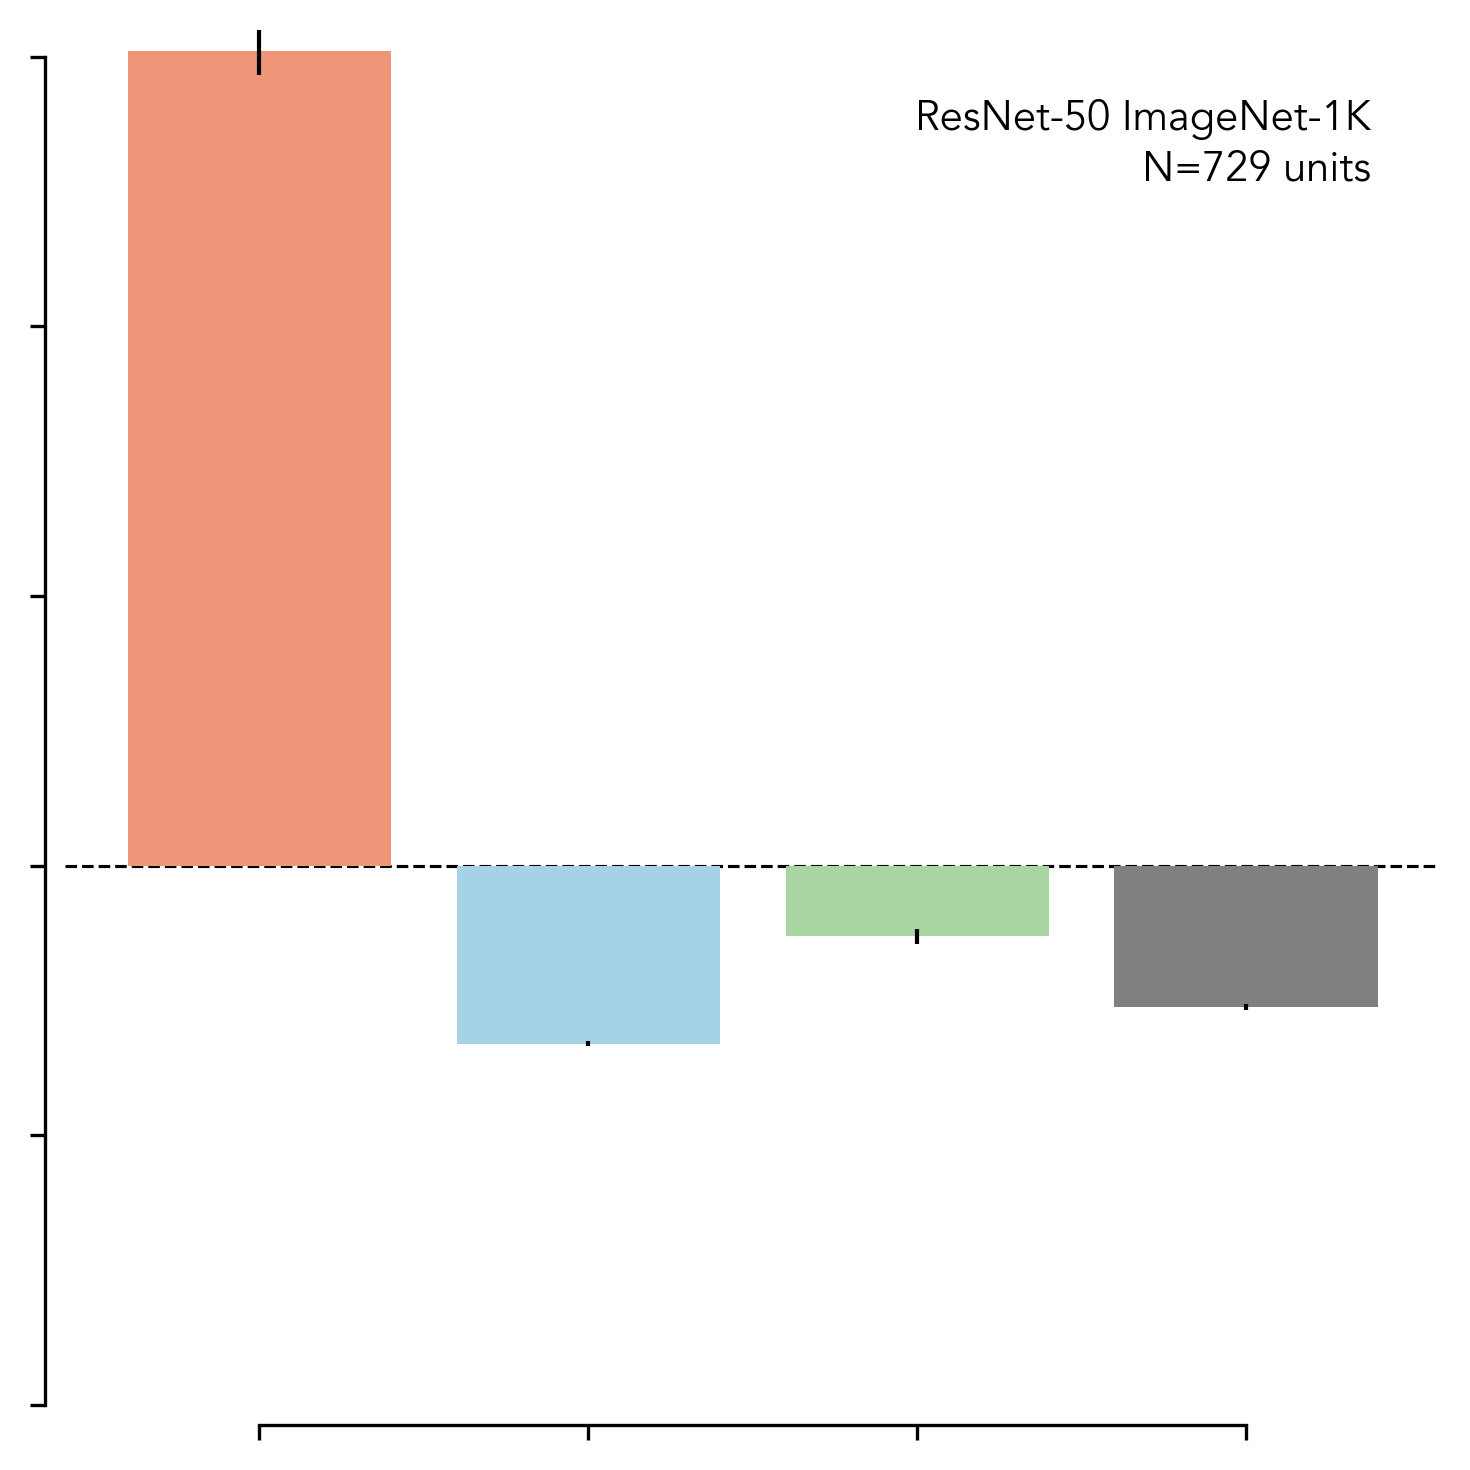

In [3]:
model_name = 'resnet50imagenet1kv2'

savefig = False

for froi in frois:
    pref_category = None
    if froi == 'FFA':
        pref_category = 'faces'
    elif froi == 'PPA':
        pref_category = 'scenes'
    elif froi == 'EBA':
        pref_category = 'bodies'
    model = ma.get_model(model_name)
    model.eval()
    print(f'Processing model: {model.name}, froi: {froi}')
    # Get number of units localized in the froi
    froi_mask = localizer.get_froi_mask(
        model_localizer_dir, model_localizer, MODELS_DIR,
        model, ma.get_froi_models_layers(froi, froi)[model.name],
        froi, tthreshold
    )
    num_units = froi_mask.sum().item()
    # FBSO
    independent_acts = model_utils.get_dataset_activations(
        MODELS_DIR, indepedent_localizer_dir, \
        model, ma.get_froi_models_layers(froi, froi)[model.name],
        dataset='localizer', localizer_type=indepedent_localizer, \
        froi=froi, tthreshold=tthreshold, \
        froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir
    )
    independent_acts_univariate = {k: v.mean(axis=-1) for k, v in independent_acts.items()}

    # Prepare data for plotting with z-scoring
    categories = list(independent_acts_univariate.keys())

    # Reorder categories and rename 'places' to 'scenes'
    # category_mapping = {'places': 'scenes', 'scrambledobjects': 'scrambled objects'}
    # display_names = [category_mapping.get(cat, cat) for cat in ordered_categories]

    # Get all activations and compute overall mean and std for z-scoring
    all_vals = torch.cat([independent_acts_univariate[cat] for cat in categories])
    overall_mean = all_vals.mean().cpu().numpy()
    overall_std = all_vals.std().cpu().numpy()

    # Compute z-scored medians and SEMs for the ordered categories
    # z_medians = [torch.median(independent_acts_univariate[cat]).cpu().numpy() for cat in ordered_categories]
    # z_sems = [torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat])) for cat in ordered_categories]
    # z_sems = None
    # z_medians = [(torch.median(independent_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
    # z_sems = [(torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat]))) / overall_std for cat in ordered_categories]
    z_means = [(torch.mean(independent_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
    z_sems = [(torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat]))) for cat in ordered_categories]

    # Set up the plot
    plt.figure(figsize=(5, 5), dpi=300)
    # Add horizontal line at z=0
    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)
    bar_positions = np.arange(len(ordered_categories))
    # bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=3, 
    #                color=['coral' if cat == pref_category else 'skyblue' for cat in ordered_categories])
    # bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=0, color='gray', error_kw={'linewidth': 1})
    bars = plt.bar(bar_positions, z_means, yerr=z_sems, capsize=0, color=ordered_colors, error_kw={'linewidth': 1})

    # Highlight the preferred category
    # for i, cat in enumerate(ordered_categories):
    #     if cat == pref_category:
    #         # bars[i].set_color('coral')
    #         bars[i].set_color('red')
    #         # bars[i].set_edgecolor('black')
    #         # bars[i].set_linewidth(1)

    # Add model name and num units to top right corner
    plt.text(0.95, 0.95, f'{MODEL_PLOTTING_NAMES[model.name]}\nN={num_units} units', 
             transform=plt.gca().transAxes, fontsize=10, ha='right', va='top', fontproperties=avenir_font)

    # Add labels and title
    # Remove top and right spines
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    # plt.xlabel('Categories', fontsize=12)
    # plt.ylabel('Z-scored Unit-averaged Activations', fontsize=12)
    # plt.title(f'ResNet50 z-scored Univariate Responses of face-selective units', fontsize=14)
    # plt.xticks(bar_positions, [cat.capitalize() for cat in ordered_categories], rotation=45)
    # plt.yticks([0, 1, 2], [0, 1, 2], fontsize=12)
    plt.yticks([-1.5, -0.75, 0, 0.75, 1.5, 2.25])
    # plt.ylim(-1.5, 2.3075)
    plt.ylim(-1.5, 2.325)
    plt.tick_params(axis='y', labelleft=False)
    # plt.gca().spines['left'].set_bounds(-0.75, 2.25)
    plt.gca().spines['left'].set_bounds(-1.5, 2.25)
    # plt.yticks([0, 1], [0, 1], fontsize=12)
    plt.xticks(bar_positions, [])
    plt.gca().spines['bottom'].set_bounds(np.arange(len(ordered_categories))[0], np.arange(len(ordered_categories))[-1])
    plt.tight_layout()

    # plt.savefig(f'{plot_dir}/model_localization_contrast_konkle_nozscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
    # plt.savefig(f'{plot_dir}/rn18imgnet_localization_contrast_konkle_zscore.png', dpi=300, bbox_inches='tight', transparent=True)
    if savefig:
        plt.savefig(f'{plot_dir}/{model.name}_{froi}_localizer_{model_localizer}_validate_{indepedent_localizer}_zscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()
    break

## ResNet50-ImageNet

Processing model: resnet50imagenet1kv2, froi: FFA


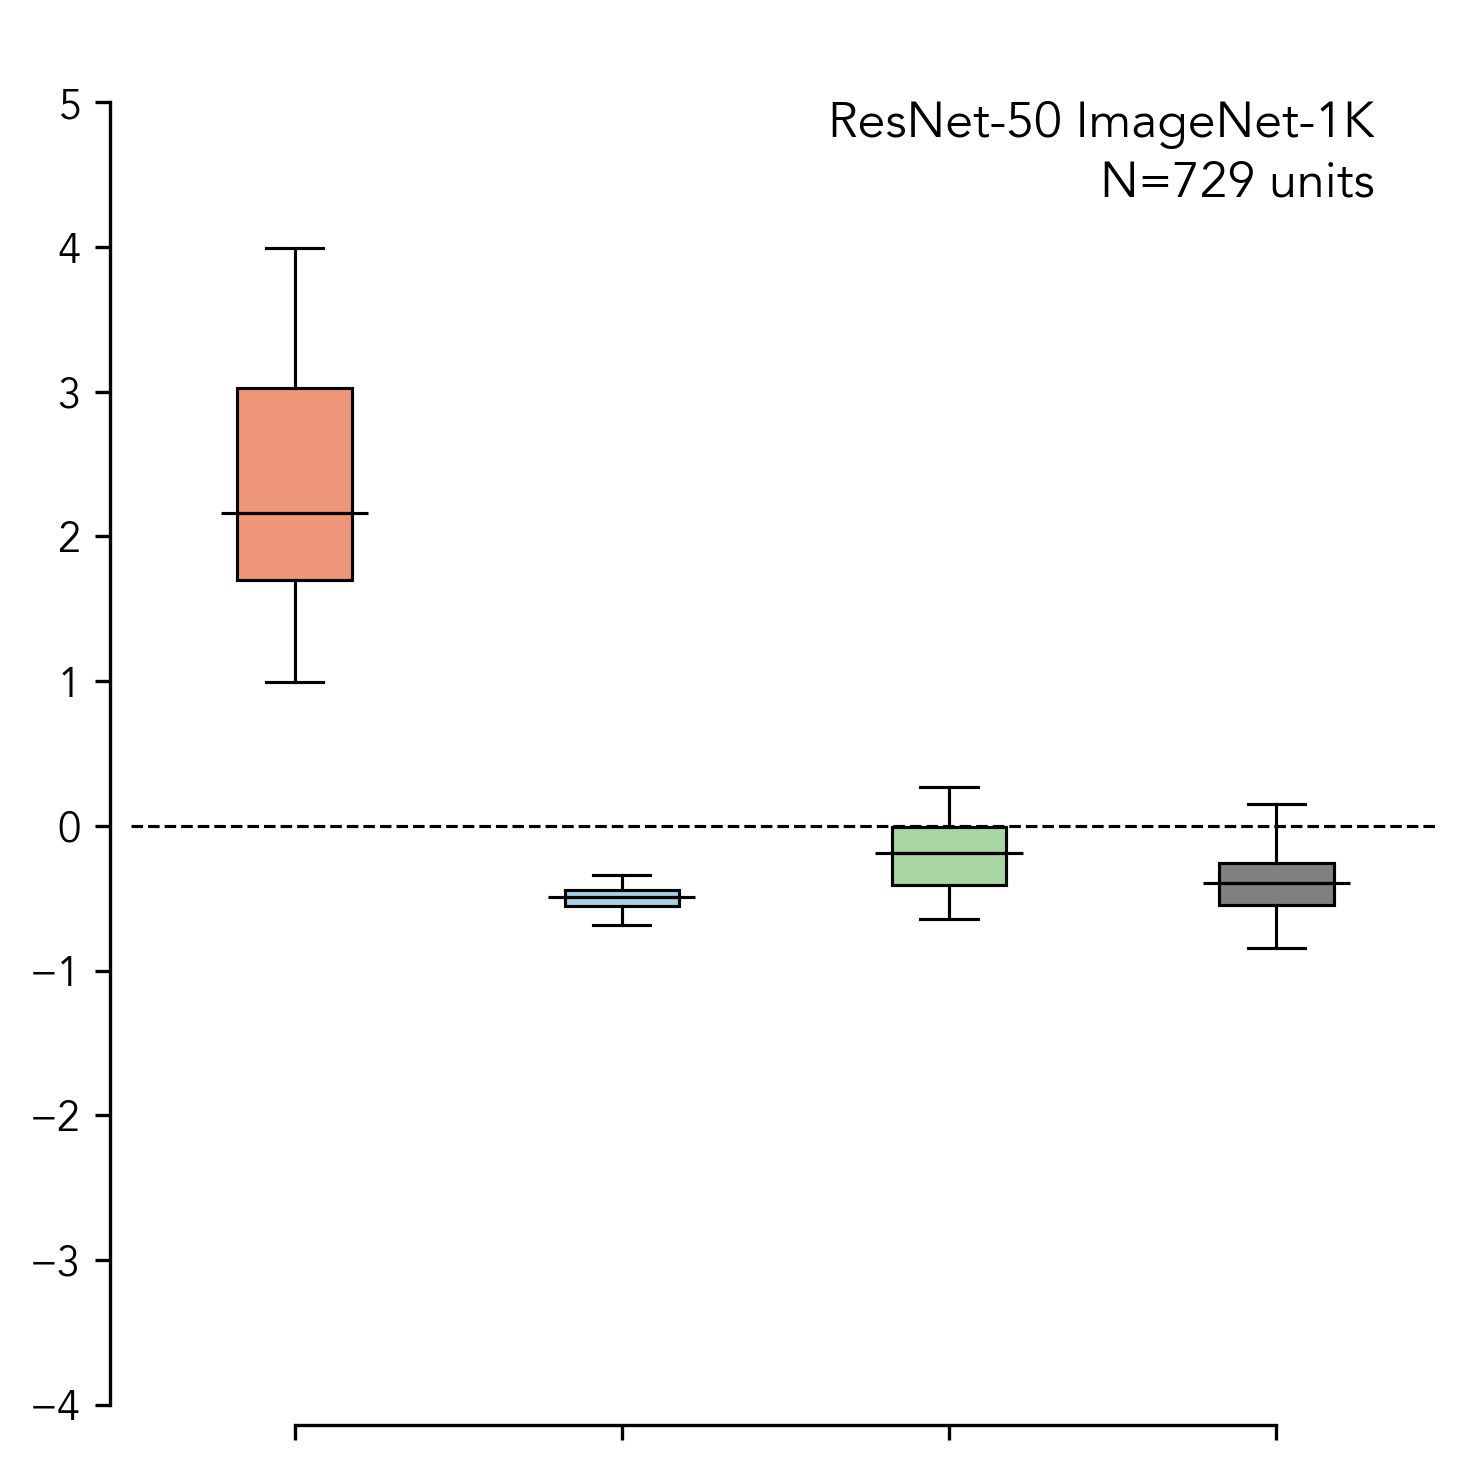

In [ ]:
model_name = 'resnet50imagenet1kv2'

tthreshold = 7
model_localizer = 'grillspector'
model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR
indepedent_localizer = 'konkle'
indepedent_localizer_dir = KONKLE_LOCALIZER_DIR

savefig = False

for froi in frois:
    pref_category = None
    if froi == 'FFA':
        pref_category = 'faces'
    elif froi == 'PPA':
        pref_category = 'scenes'
    elif froi == 'EBA':
        pref_category = 'bodies'
    model = ma.get_model(model_name)
    model.eval()
    print(f'Processing model: {model.name}, froi: {froi}')
    # Get number of units localized in the froi
    froi_mask = localizer.get_froi_mask(
        model_localizer_dir, model_localizer, MODELS_DIR,
        model, ma.get_froi_models_layers(froi, froi)[model.name],
        froi, tthreshold
    )
    num_units = froi_mask.sum().item()
    # FBSO
    independent_acts = model_utils.get_dataset_activations(
        MODELS_DIR, indepedent_localizer_dir, \
        model, ma.get_froi_models_layers(froi, froi)[model.name],
        dataset='localizer', localizer_type=indepedent_localizer, \
        froi=froi, tthreshold=tthreshold, \
        froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir
    )
    independent_acts_univariate = {k: v.mean(axis=-1) for k, v in independent_acts.items()}

    # Prepare data for plotting with z-scoring
    categories = list(independent_acts_univariate.keys())

    # Reorder categories and rename 'places' to 'scenes'
    # category_mapping = {'places': 'scenes', 'scrambledobjects': 'scrambled objects'}
    # display_names = [category_mapping.get(cat, cat) for cat in ordered_categories]

    # Get all activations and compute overall mean and std for z-scoring
    all_vals = torch.cat([independent_acts_univariate[cat] for cat in categories])
    overall_mean = all_vals.mean().cpu().numpy()
    overall_std = all_vals.std().cpu().numpy()

    # Compute z-scored medians and SEMs for the ordered categories
    # z_medians = [torch.median(independent_acts_univariate[cat]).cpu().numpy() for cat in ordered_categories]
    # z_sems = [torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat])) for cat in ordered_categories]
    # z_sems = None
    # z_medians = [(torch.median(independent_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
    # z_sems = [(torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat]))) / overall_std for cat in ordered_categories]
    z_means = [(torch.mean(independent_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
    z_sems = [(torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat]))) for cat in ordered_categories]

    # Set up the plot
    plt.figure(figsize=(5, 5), dpi=300)
    # Add horizontal line at z=0
    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)
    # bar_positions = np.arange(len(ordered_categories))
    # # bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=3, 
    # #                color=['coral' if cat == pref_category else 'skyblue' for cat in ordered_categories])
    # # bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=0, color='gray', error_kw={'linewidth': 1})
    # bars = plt.bar(bar_positions, z_means, yerr=z_sems, capsize=0, color=ordered_colors, error_kw={'linewidth': 1})
    # Box plot
    # Box plot data preparation
    box_data = []
    for cat in ordered_categories:
        # Z-score the data for each category
        cat_data = (independent_acts_univariate[cat].cpu().numpy() - overall_mean) / overall_std
        box_data.append(cat_data)
    
    # Create the box plot
    linewidth = 0.75
    bar_positions = np.arange(len(ordered_categories))
    barwidth = 0.35
    boxes = plt.boxplot(
                box_data, positions=bar_positions, patch_artist=True, 
                widths=barwidth, showfliers=False,
                boxprops={'color': 'black', 'linewidth': linewidth},
                whiskerprops=dict(linewidth=linewidth),
                capprops=dict(linewidth=linewidth),
                medianprops={'color': 'black', 'linewidth': linewidth},
                flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
            )
    for i, data in enumerate(box_data):
        med = np.median(data)
        # Manually draw a longer median line
        x = bar_positions[i]  # X-position of the boxplot
        plt.plot([x - 0.225, x + 0.225], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
    
    # Color the boxes according to category colors
    for box, color, cat in zip(boxes['boxes'], ordered_colors, ordered_categories):
        box.set(facecolor=color)
        # if cat == pref_category:
        #     box.set(linewidth=1.5, edgecolor='black')
        # else:
        #     box.set(linewidth=1, edgecolor='gray')

    # Add model name and num units to top right corner
    plt.text(0.95, 0.95, f'{MODEL_PLOTTING_NAMES[model.name]}\nN={num_units} units', 
             transform=plt.gca().transAxes, fontsize=12, ha='right', va='top', fontproperties=avenir_font)

    # Add labels and title
    # Remove top and right spines
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    # plt.xlabel('Categories', fontsize=12)
    # plt.ylabel('Z-scored Unit-averaged Activations', fontsize=12)
    # plt.yticks([-1.5, -0.75, 0, 0.75, 1.5, 2.25])
    plt.yticks([-4, -3, -2, -1, 0, 1, 2, 3, 4, 5])
    # plt.ylim(-1.5, 2.325)
    # plt.ylim(-2, 4.5)
    plt.ylim(-4, 5.5)
    # plt.tick_params(axis='y', labelleft=False)
    # plt.gca().spines['left'].set_bounds(-1.5, 2.25)
    # plt.gca().spines['left'].set_bounds(-2, 4)
    plt.gca().spines['left'].set_bounds(-4, 5)
    # plt.yticks([0, 1], [0, 1], fontsize=12)
    plt.xticks(bar_positions, [])
    plt.gca().spines['bottom'].set_bounds(np.arange(len(ordered_categories))[0], np.arange(len(ordered_categories))[-1])
    plt.tight_layout()

    # plt.savefig(f'{plot_dir}/model_localization_contrast_konkle_nozscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
    # plt.savefig(f'{plot_dir}/rn18imgnet_localization_contrast_konkle_zscore.png', dpi=300, bbox_inches='tight', transparent=True)
    if savefig:
        plt.savefig(f'{plot_dir}/fig2_{model.name}_{froi}_localizer_{model_localizer}_validate_{indepedent_localizer}_zscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()
    break

## 4 models

In [ ]:
model_names = list(set(ma.get_model_names()) - set(['resnet50imagenet1kv2']))

tthreshold = 7
model_localizer = 'grillspector'
model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR
indepedent_localizer = 'konkle'
indepedent_localizer_dir = KONKLE_LOCALIZER_DIR

savefig = True

for froi in frois:
    pref_category = None
    if froi == 'FFA':
        pref_category = 'faces'
    elif froi == 'PPA':
        pref_category = 'scenes'
    elif froi == 'EBA':
        pref_category = 'bodies'
    fig, axes = plt.subplots(2, 17, figsize=(5*17, 5*2), dpi=300)
    axes = axes.flatten()
    for midx, model_name in enumerate(model_names):
        ax = axes[midx]
        model = ma.get_model(model_name)
        model.eval()
        print(f'Processing model: {model.name}, froi: {froi}')
        # Get number of units localized in the froi
        froi_mask = localizer.get_froi_mask(
            model_localizer_dir, model_localizer, MODELS_DIR,
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            froi, tthreshold
        )
        num_units = froi_mask.sum().item()
        # FBSO
        independent_acts = model_utils.get_dataset_activations(
            MODELS_DIR, indepedent_localizer_dir, \
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            dataset='localizer', localizer_type=indepedent_localizer, \
            froi=froi, tthreshold=tthreshold, \
            froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir
        )
        independent_acts_univariate = {k: v.mean(axis=-1) for k, v in independent_acts.items()}

        # Prepare data for plotting with z-scoring
        categories = list(independent_acts_univariate.keys())

        # Get all activations and compute overall mean and std for z-scoring
        all_vals = torch.cat([independent_acts_univariate[cat] for cat in categories])
        overall_mean = all_vals.mean().cpu().numpy()
        overall_std = all_vals.std().cpu().numpy()

        # Set up the plot
        # Add horizontal line at z=0
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)
        # Box plot
        # Box plot data preparation
        box_data = []
        for cat in ordered_categories:
            # Z-score the data for each category
            cat_data = (independent_acts_univariate[cat].cpu().numpy() - overall_mean) / overall_std
            box_data.append(cat_data)
        
        # Create the box plot
        linewidth = 0.75
        bar_positions = np.arange(len(ordered_categories))
        barwidth = 0.35
        boxes = ax.boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth),
                    capprops=dict(linewidth=linewidth),
                    medianprops={'color': 'black', 'linewidth': linewidth},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            ax.plot([x - 0.225, x + 0.225], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
        
        # Color the boxes according to category colors
        for box, color, cat in zip(boxes['boxes'], ordered_colors, ordered_categories):
            box.set(facecolor=color)

        # Add model name and num units to top right corner
        ax.text(0.95, 0.95, f'{MODEL_PLOTTING_NAMES[model.name]}\nN={num_units} units', 
                transform=ax.transAxes, fontsize=12, ha='right', va='top', fontproperties=avenir_font)

        # Add labels and title
        # Remove top and right spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.set_yticks([-4, -3, -2, -1, 0, 1, 2, 3, 4, 5])
        # plt.ylim(-1.5, 2.325)
        ax.set_ylim(-4, 5.5)
        ax.tick_params(axis='y', labelleft=False)
        # plt.gca().spines['left'].set_bounds(-1.5, 2.25)
        ax.spines['left'].set_bounds(-4, 5)
        # plt.yticks([0, 1], [0, 1], fontsize=12)
        ax.set_xticks(bar_positions, [])
        ax.spines['bottom'].set_bounds(np.arange(len(ordered_categories))[0], np.arange(len(ordered_categories))[-1])
    fig.tight_layout()
    # plt.savefig(f'{plot_dir}/model_localization_contrast_konkle_nozscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
    # plt.savefig(f'{plot_dir}/rn18imgnet_localization_contrast_konkle_zscore.png', dpi=300, bbox_inches='tight', transparent=True)
    if savefig:
        plt.savefig(f'{plot_dir}/fig2_manymodels_{froi}_localizer_{model_localizer}_validate_{indepedent_localizer}_zscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

Processing model: vitb32openaiclip, froi: FFA
Processing model: alexnetbarlowtwins, froi: FFA
Processing model: resnet50cesslbarlowtop, froi: FFA
Processing model: vitl14kosmos2, froi: FFA
Processing model: vitl14openaiclip, froi: FFA


Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


Processing model: alexnetipclref01, froi: FFA


Processing model: vitb16synclr, froi: FFA
Processing model: vitb16imagenet21k, froi: FFA
Processing model: cornetz, froi: FFA
Processing model: resnet18tdannsimclrlw1, froi: FFA
Processing model: convnexttinyimagenet1kv1, froi: FFA
Processing model: bagnet33, froi: FFA
Processing model: resnet101openaiclip, froi: FFA
Processing model: resnet50faceobfuscation, froi: FFA
Processing model: resnet101imagenet1kv1, froi: FFA
Processing model: resnet18tdannsupervisedlw10, froi: FFA
Processing model: vitb16eva028bs8bb131k, froi: FFA
/home/alishd/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar
Processing model: resnet50simclr, froi: FFA
Processing model: resnet50openaiclip, froi: FFA
Processing model: resnet50ecoset, froi: FFA


Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main


...

Processing model: vitb14dinov2, froi: EBA
Processing model: resnet18imagenet1kv1, froi: EBA
Processing model: vitb16siglip2res224, froi: EBA
Processing model: cornets, froi: EBA


/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Processing model: resnet50toponettau30, froi: EBA
Processing model: resnet50sin, froi: EBA
Processing model: vitb16openaiclip, froi: EBA


Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main


Processing model: vitb14dinov2reg, froi: EBA
Processing model: resnet50blurstrong, froi: EBA
Processing model: alexnetimagenet1kv1, froi: EBA
Processing model: vgg16imagenet1kv1, froi: EBA
Using cached ./models
Processing model: vitb32dreamsimopenclip, froi: EBA
Processing model: resnet50robustl2eps3, froi: EBA
Processing model: vitb32imagenet1kv1, froi: EBA


## 30 models

# Fig 3

In [21]:
tthreshold = 7
frois = ['FFA', 'PPA', 'EBA']
model_localizer = 'grillspector'
froi_comparisons = {
    'FFA': ['OFA', 'EBA', 'PPA'],
    'EBA': ['FBA', 'FFA', 'PPA'],
    'PPA': ['OPA', 'RSC', 'FFA'],
}

FROIFROI_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/froifroi_correlations_nsd515.csv'
SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'

taskoptimized_model_names = ma.get_model_names('task_optimized')

## Stats

In [ ]:
# Subject - Subject correlations
subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)

# for each fROI calculate the median correlation

# Median across all subject pairs & minimum
subjectsubject_correlations_csv_ = subjectsubject_correlations_csv[
    (subjectsubject_correlations_csv['fmri_froi'].isin(frois)) & 
    (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
]
for froi in frois:
    froi_df = subjectsubject_correlations_csv_[subjectsubject_correlations_csv_['fmri_froi'] == froi]
    median_corr = froi_df['normed_pearsonr'].median()
    min_corr = froi_df['normed_pearsonr'].min()
    print(f'{froi} Univariate comparison - Median correlation: {median_corr}, Min correlation: {min_corr}')
    median_corr = froi_df['normed_rdmr'].median()
    min_corr = froi_df['normed_rdmr'].min()
    print(f'{froi} Multivariate comparison - Median correlation: {median_corr}, Min correlation: {min_corr}')
# print(f'median of froi medians univariate: {np.median([0.9835081012617362, 1.014473855009372, 0.997636511462672])}')
print('\n')

# Across fROIs
median_corr = subjectsubject_correlations_csv_['normed_pearsonr'].median()
min_corr = subjectsubject_correlations_csv_['normed_pearsonr'].min()
print(f'Collated across fROIs Univariate comparison - Median correlation: {median_corr}, Min correlation: {min_corr}')
median_corr = subjectsubject_correlations_csv_['normed_rdmr'].median()
min_corr = subjectsubject_correlations_csv_['normed_rdmr'].min()
print(f'Collated across fROIs Multivariate comparison - Median correlation: {median_corr}, Min correlation: {min_corr}')

FFA Univariate comparison - Median correlation: 0.9835081012617362, Min correlation: 0.8727959208707898
FFA Multivariate comparison - Median correlation: 1.0096695737095467, Min correlation: 0.8050828196815112
PPA Univariate comparison - Median correlation: 1.014473855009372, Min correlation: 0.951006226674186
PPA Multivariate comparison - Median correlation: 1.0690142237039242, Min correlation: 0.8809373944824533
EBA Univariate comparison - Median correlation: 0.997636511462672, Min correlation: 0.8789127532362431
EBA Multivariate comparison - Median correlation: 1.127443932787022, Min correlation: 0.971870788105894


Collated across fROIs Univariate comparison - Median correlation: 0.9960939017125654, Min correlation: 0.8727959208707898
Collated across fROIs Multivariate comparison - Median correlation: 1.0485724866119113, Min correlation: 0.8050828196815112


In [86]:
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)
# Median across all models (one point is median of model with all subjects) & maximum
modelsubject_correlations_csv_ = modelsubject_correlations_csv[
    (modelsubject_correlations_csv['fmri_froi'].isin(frois)) & 
    (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
]
# Group by model and froi, then take the median of the normed pearson r
modelsubject_correlations_csv_grouped = modelsubject_correlations_csv_.groupby(
    ['model_name', 'fmri_froi']
).agg({'normed_pearsonr': 'median', 'normed_rdmr': 'median'}).reset_index()
subjectsubject_correlations_csv_grouped = subjectsubject_correlations_csv_.groupby(
    ['fmri_froi']
).agg({'normed_pearsonr': 'median', 'normed_rdmr': 'median'}).reset_index()
print(subjectsubject_correlations_csv_grouped)
print('\n')

# Get the median and maximum of the normed pearson r and normed RDM r for every fmri froi
for froi in frois:
    print(f'FROI: {froi}')
    froi_grouped = modelsubject_correlations_csv_grouped[modelsubject_correlations_csv_grouped['fmri_froi'] == froi]
    print(f'Median model-subject normed pearson r for {froi}: {froi_grouped['normed_pearsonr'].median()}')
    print(f'Maximum model-subject normed pearson r for {froi}: {froi_grouped['normed_pearsonr'].max()}')
    print(f'Median model-subject normed RDM r for {froi}: {froi_grouped['normed_rdmr'].median()}')
    print(f'Maximum model-subject normed RDM r for {froi}: {froi_grouped['normed_rdmr'].max()}')
    print('\n')

# Get rows with the maximum normed pearson r for each model and froi
modelsubject_correlations_csv_max = modelsubject_correlations_csv_grouped.loc[
    modelsubject_correlations_csv_grouped.groupby(['fmri_froi'])['normed_pearsonr'].idxmax()
]
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.reset_index(drop=True)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.rename(
    columns={'normed_pearsonr': 'max_normed_pearsonr', 'normed_rdmr': 'max_normed_rdmr'}
)
print(modelsubject_correlations_csv_max)

# Get rows with the maximum normed pearson r for each model and froi
modelsubject_correlations_csv_max = modelsubject_correlations_csv_grouped.loc[
    modelsubject_correlations_csv_grouped.groupby(['fmri_froi'])['normed_rdmr'].idxmax()
]
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.reset_index(drop=True)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.rename(
    columns={'normed_pearsonr': 'max_normed_pearsonr', 'normed_rdmr': 'max_normed_rdmr'}
)
print(modelsubject_correlations_csv_max)

print('\n')
print(f'FFA gap: {0.983508 - 0.6182962524942974}')
print(f'PPA gap: {1.014474 - 0.7269798643138887}')
print(f'EBA gap: {0.997637 - 0.6727995765455339}')
print('\n')
print('Gap for the best model (ResNet101-CLIP) in each fROI:')
print(modelsubject_correlations_csv_grouped[
    modelsubject_correlations_csv_grouped['model_name'] == 'resnet101openaiclip'
])
print(f'FFA gap: {0.983508 - 0.771309}')
print(f'PPA gap: {1.014474 - 0.774940}')
print(f'EBA gap: {0.997637 - 0.729405}')
print('\n')

print('Best model overall according to pearson correlation:')
modelsubject_correlations_csv_grouped_froimedian = modelsubject_correlations_csv_grouped.groupby(
    ['model_name']
).agg({'normed_pearsonr': 'median', 'normed_rdmr': 'median'}).reset_index()
# Find the model with the maximum median normed pearson r
modelsubject_correlations_csv_max = modelsubject_correlations_csv_grouped_froimedian.loc[
    modelsubject_correlations_csv_grouped_froimedian.groupby(['model_name'])['normed_pearsonr'].idxmax()
]
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.reset_index(drop=True)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.rename(
    columns={'normed_pearsonr': 'max_normed_pearsonr', 'normed_rdmr': 'max_normed_rdmr'}
)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.sort_values(by='max_normed_pearsonr', ascending=False)
print(modelsubject_correlations_csv_max)
print('\n\n')

print('Best model overall according to RDM correlation:')
# Find the model with the maximum median normed RDM r
modelsubject_correlations_csv_max = modelsubject_correlations_csv_grouped_froimedian.loc[
    modelsubject_correlations_csv_grouped_froimedian.groupby(['model_name'])['normed_rdmr'].idxmax()
]
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.reset_index(drop=True)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.rename(
    columns={'normed_pearsonr': 'max_normed_pearsonr', 'normed_rdmr': 'max_normed_rdmr'}
)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.sort_values(by='max_normed_rdmr', ascending=False)
print(modelsubject_correlations_csv_max)

  fmri_froi  normed_pearsonr  normed_rdmr
0       EBA         0.997637     1.127444
1       FFA         0.983508     1.009670
2       PPA         1.014474     1.069014


FROI: FFA
Median model-subject normed pearson r for FFA: 0.6182962524942974
Maximum model-subject normed pearson r for FFA: 0.7881708912052379
Median model-subject normed RDM r for FFA: 0.3834384870617388
Maximum model-subject normed RDM r for FFA: 0.5962871620757758


FROI: PPA
Median model-subject normed pearson r for PPA: 0.7269798643138887
Maximum model-subject normed pearson r for PPA: 0.8145883613673137
Median model-subject normed RDM r for PPA: 0.36788912124436585
Maximum model-subject normed RDM r for PPA: 0.5854834524656816


FROI: EBA
Median model-subject normed pearson r for EBA: 0.6727995765455339
Maximum model-subject normed pearson r for EBA: 0.773689940166435
Median model-subject normed RDM r for EBA: 0.30661100758154636
Maximum model-subject normed RDM r for EBA: 0.6082541102575543


              model

,model_name,fmri_froi,normed_pearsonr,normed_rdmr
24,resnet101openaiclip,EBA,0.729405,0.556596
25,resnet101openaiclip,FFA,0.771309,0.539668
26,resnet101openaiclip,PPA,0.774940,0.274159


In [ ]:
subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

frois = ['FFA', 'PPA', 'EBA']

# Median across all subject pairs & minimum
subjectsubject_correlations_csv_ = subjectsubject_correlations_csv[
    (subjectsubject_correlations_csv['fmri_froi'].isin(frois)) & 
    (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
]
print(f'Median subject-subject normed pearson r: {subjectsubject_correlations_csv_['normed_pearsonr'].median()}')
print(f'Minimum subject-subject normed pearson r: {subjectsubject_correlations_csv_['normed_pearsonr'].min()}')
print(f'Median subject-subject normed RDM r: {subjectsubject_correlations_csv_['normed_rdmr'].median()}')
print(f'Minimum subject-subject normed RDM r: {subjectsubject_correlations_csv_['normed_rdmr'].min()}')
print('\n')

# Median across all models (one point is median of model with all subjects) & maximum
modelsubject_correlations_csv_ = modelsubject_correlations_csv[
    (modelsubject_correlations_csv['fmri_froi'].isin(frois)) & 
    (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
]
# Group by model and froi, then take the median of the normed pearson r
modelsubject_correlations_csv_grouped = modelsubject_correlations_csv_.groupby(
    ['model_name', 'fmri_froi']
).agg({'normed_pearsonr': 'median', 'normed_rdmr': 'median'}).reset_index()
subjectsubject_correlations_csv_grouped = subjectsubject_correlations_csv_.groupby(
    ['fmri_froi']
).agg({'normed_pearsonr': 'median', 'normed_rdmr': 'median'}).reset_index()
print(subjectsubject_correlations_csv_grouped)
print('\n')

# Get the median and maximum of the normed pearson r and normed RDM r for every fmri froi
for froi in frois:
    print(f'FROI: {froi}')
    froi_grouped = modelsubject_correlations_csv_grouped[modelsubject_correlations_csv_grouped['fmri_froi'] == froi]
    print(f'Median model-subject normed pearson r for {froi}: {froi_grouped['normed_pearsonr'].median()}')
    print(f'Maximum model-subject normed pearson r for {froi}: {froi_grouped['normed_pearsonr'].max()}')
    print(f'Median model-subject normed RDM r for {froi}: {froi_grouped['normed_rdmr'].median()}')
    print(f'Maximum model-subject normed RDM r for {froi}: {froi_grouped['normed_rdmr'].max()}')
    print('\n')
# print(f'Median model-subject normed pearson r: {modelsubject_correlations_csv_grouped['normed_pearsonr'].median()}')
# print(f'Maximum model-subject normed pearson r: {modelsubject_correlations_csv_grouped['normed_pearsonr'].max()}')
# print(f'Median model-subject normed RDM r: {modelsubject_correlations_csv_grouped['normed_rdmr'].median()}')
# print(f'Maximum model-subject normed RDM r: {modelsubject_correlations_csv_grouped['normed_rdmr'].max()}')

# Get rows with the maximum normed pearson r for each model and froi
modelsubject_correlations_csv_max = modelsubject_correlations_csv_grouped.loc[
    modelsubject_correlations_csv_grouped.groupby(['fmri_froi'])['normed_pearsonr'].idxmax()
]
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.reset_index(drop=True)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.rename(
    columns={'normed_pearsonr': 'max_normed_pearsonr', 'normed_rdmr': 'max_normed_rdmr'}
)
print(modelsubject_correlations_csv_max)

# Get rows with the maximum normed pearson r for each model and froi
modelsubject_correlations_csv_max = modelsubject_correlations_csv_grouped.loc[
    modelsubject_correlations_csv_grouped.groupby(['fmri_froi'])['normed_rdmr'].idxmax()
]
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.reset_index(drop=True)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.rename(
    columns={'normed_pearsonr': 'max_normed_pearsonr', 'normed_rdmr': 'max_normed_rdmr'}
)
print(modelsubject_correlations_csv_max)

print('\n')
print(f'FFA gap: {0.983508 - 0.6182962524942974}')
print(f'PPA gap: {1.014474 - 0.7269798643138887}')
print(f'EBA gap: {0.997637 - 0.6727995765455339}')

print('\n')
print('Best model overall according to pearson correlation:')
modelsubject_correlations_csv_max = modelsubject_correlations_csv_grouped.loc[
    modelsubject_correlations_csv_grouped.groupby(['model_name'])['normed_pearsonr'].idxmax()
]
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.reset_index(drop=True)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.rename(
    columns={'normed_pearsonr': 'max_normed_pearsonr', 'normed_rdmr': 'max_normed_rdmr'}
)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.sort_values(by='max_normed_pearsonr', ascending=False)
print(modelsubject_correlations_csv_max)

print('\n')
print('Best model overall according to rdm correlation:')
modelsubject_correlations_csv_max = modelsubject_correlations_csv_grouped.loc[
    modelsubject_correlations_csv_grouped.groupby(['model_name'])['normed_rdmr'].idxmax()
]
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.reset_index(drop=True)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.rename(
    columns={'normed_pearsonr': 'max_normed_pearsonr', 'normed_rdmr': 'max_normed_rdmr'}
)
modelsubject_correlations_csv_max = modelsubject_correlations_csv_max.sort_values(by='max_normed_rdmr', ascending=False)
print(modelsubject_correlations_csv_max)

Median subject-subject normed pearson r: 0.9960939017125654
Minimum subject-subject normed pearson r: 0.8727959208707898
Median subject-subject normed RDM r: 1.0485724866119113
Minimum subject-subject normed RDM r: 0.8050828196815112


  fmri_froi  normed_pearsonr  normed_rdmr
0       EBA         0.997637     1.127444
1       FFA         0.983508     1.009670
2       PPA         1.014474     1.069014


FROI: FFA
Median model-subject normed pearson r for FFA: 0.6182962524942974
Maximum model-subject normed pearson r for FFA: 0.7881708912052379
Median model-subject normed RDM r for FFA: 0.3834384870617388
Maximum model-subject normed RDM r for FFA: 0.5962871620757758


FROI: PPA
Median model-subject normed pearson r for PPA: 0.7269798643138887
Maximum model-subject normed pearson r for PPA: 0.8145883613673137
Median model-subject normed RDM r for PPA: 0.36788912124436585
Maximum model-subject normed RDM r for PPA: 0.5854834524656816


FROI: EBA
Median model-subject normed pearson r for E

In [38]:
modelsubject_correlations_csv_

,model_name,model_layer,model_froi,model_tthreshold,model_localizer,fmri_dataset,fmri_froi,fmri_tthreshold,subject,normed_pearsonr,pearsonr,normed_rdmr,rdmr,pvalue_rdmr,pvalue_pearsonr,fmri_splithalf_pearsonr,fmri_splithalf_rdmr
0,alexnetimagenet1kv1,features.11,FFA,7,grillspector,nsd515,FFA,7,1,0.579079,0.524384,0.356567,0.264244,0.0,1.011229e-37,0.820017,0.549200
2,alexnetimagenet1kv1,features.12,EBA,7,grillspector,nsd515,EBA,7,1,0.509453,0.457236,0.259660,0.194928,0.0,5.709499e-28,0.805513,0.563560
4,alexnetimagenet1kv1,features.12,PPA,7,grillspector,nsd515,PPA,7,1,0.619488,0.538884,0.198041,0.131808,0.0,3.969849e-40,0.756702,0.442968
7,alexnetimagenet1kv1,features.11,FFA,7,grillspector,nsd515,FFA,7,2,0.657376,0.597486,0.502901,0.380867,0.0,3.774516e-51,0.826090,0.573563
9,alexnetimagenet1kv1,features.12,EBA,7,grillspector,nsd515,EBA,7,2,0.496988,0.431335,0.269299,0.192396,0.0,9.474955e-25,0.753248,0.510411
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1948,convnexttinyimagenet1kv1,features.5.7.block.3,EBA,7,grillspector,nsd515,EBA,7,7,0.724770,0.612722,0.519005,0.346175,0.0,2.113391e-54,0.714703,0.444887
1950,convnexttinyimagenet1kv1,features.5.2.block.3,PPA,7,grillspector,nsd515,PPA,7,7,0.806977,0.595580,0.595779,0.281019,0.0,9.363155e-51,0.544700,0.222485
1953,convnexttinyimagenet1kv1,features.5.7.block.3,FFA,7,grillspector,nsd515,FFA,7,8,0.627813,0.505135,0.472118,0.276250,0.0,1.058845e-34,0.647372,0.342375
1955,convnexttinyimagenet1kv1,features.5.7.block.3,EBA,7,grillspector,nsd515,EBA,7,8,0.724700,0.516433,0.671391,0.305870,0.0,1.886664e-36,0.507821,0.207550


In [39]:
modelsubject_correlations_csv_grouped = modelsubject_correlations_csv_.groupby(
    ['model_name', 'fmri_froi']
).agg({'normed_pearsonr': 'median', 'normed_rdmr': 'median'}).reset_index()
modelsubject_correlations_csv_grouped

,model_name,fmri_froi,normed_pearsonr,normed_rdmr
0,alexnetbarlowtwins,EBA,0.544135,0.277098
1,alexnetbarlowtwins,FFA,0.547911,0.325984
2,alexnetbarlowtwins,PPA,0.684246,0.393791
3,alexnetimagenet1kv1,EBA,0.515209,0.274042
4,alexnetimagenet1kv1,FFA,0.596958,0.474316
...,...,...,...,...
100,vitl14kosmos2,FFA,0.667931,0.236406
101,vitl14kosmos2,PPA,0.739370,0.369011
102,vitl14openaiclip,EBA,0.665532,0.278161
103,vitl14openaiclip,FFA,0.679039,0.553965


In [32]:
models = modelsubject_correlations_csv['model_name'].unique()

for froi in frois:
    print(froi)
    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        model_median = modelsubject_froi['normed_pearsonr'].median()
        print(f'Model: {model}, Median normed pearson r: {model_median}')
    print('\n\n')

FFA
Model: alexnetimagenet1kv1, Median normed pearson r: 0.5969582682074377
Model: alexnetipclref01, Median normed pearson r: 0.4507841158432217
Model: alexnetbarlowtwins, Median normed pearson r: 0.5479106676086561
Model: vgg16imagenet1kv1, Median normed pearson r: 0.7112384491820667
Model: resnet18imagenet1kv1, Median normed pearson r: 0.551174864596826
Model: resnet50imagenet1kv2, Median normed pearson r: 0.7069041492838903
Model: resnet50openaiclip, Median normed pearson r: 0.7881708912052379
Model: resnet50simclr, Median normed pearson r: 0.6183680373114442
Model: resnet50robustl2eps3, Median normed pearson r: 0.552907773195883
Model: resnet50sin, Median normed pearson r: 0.5823910545032773
Model: resnet50ecoset, Median normed pearson r: 0.6421502375545953
Model: resnet50faceobfuscation, Median normed pearson r: 0.5376793546214154
Model: resnet50toponettau30, Median normed pearson r: 0.6929132454988918
Model: resnet101imagenet1kv1, Median normed pearson r: 0.6182962524942974
Model

## Dev

### Box plot

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 22.58, p-value: 1.06e-28


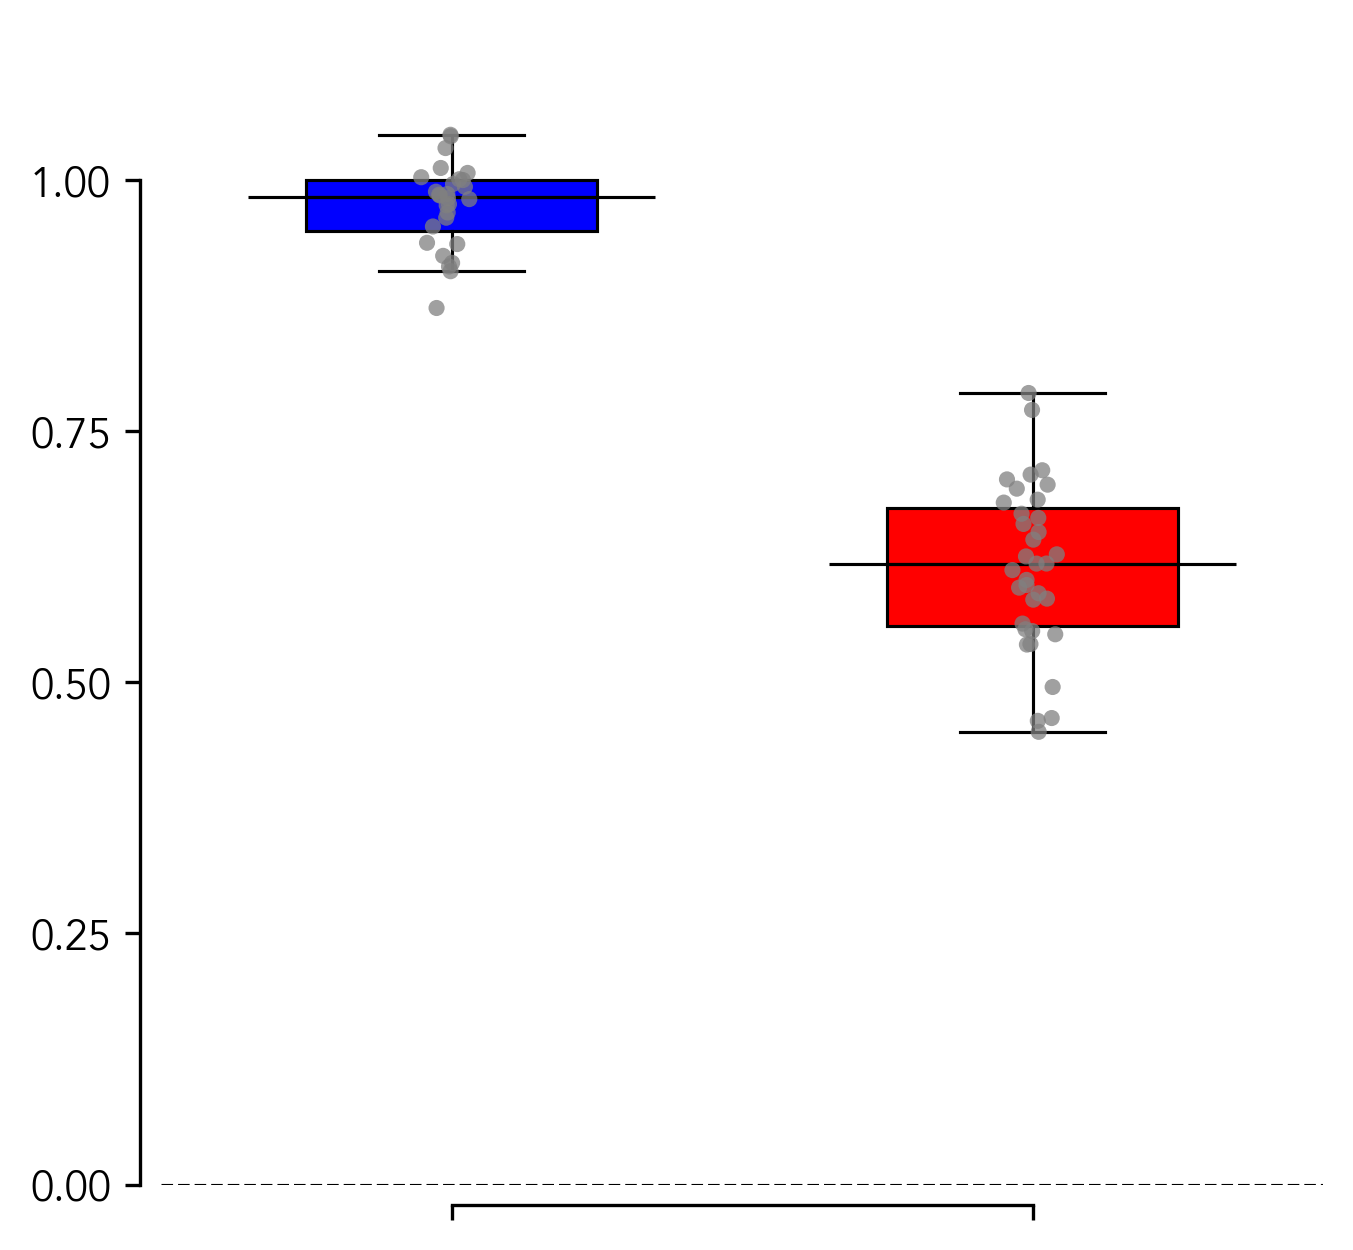

PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 21.38, p-value: 1.73e-29


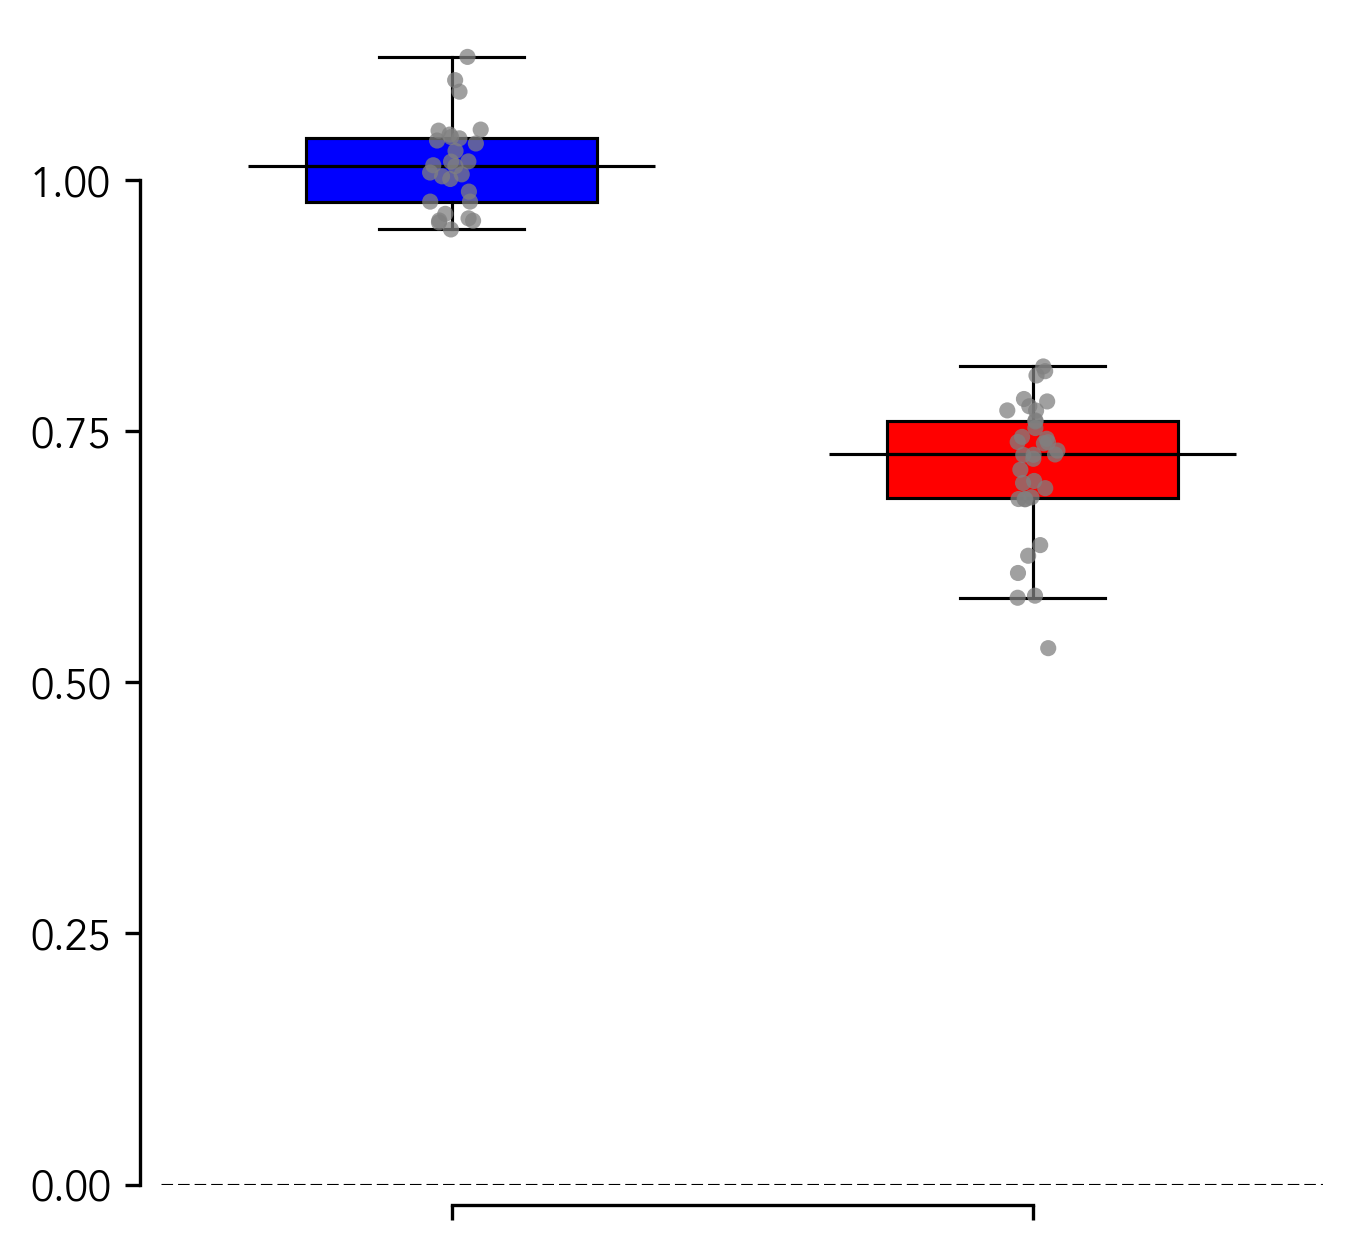

EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 19.57, p-value: 1.19e-26


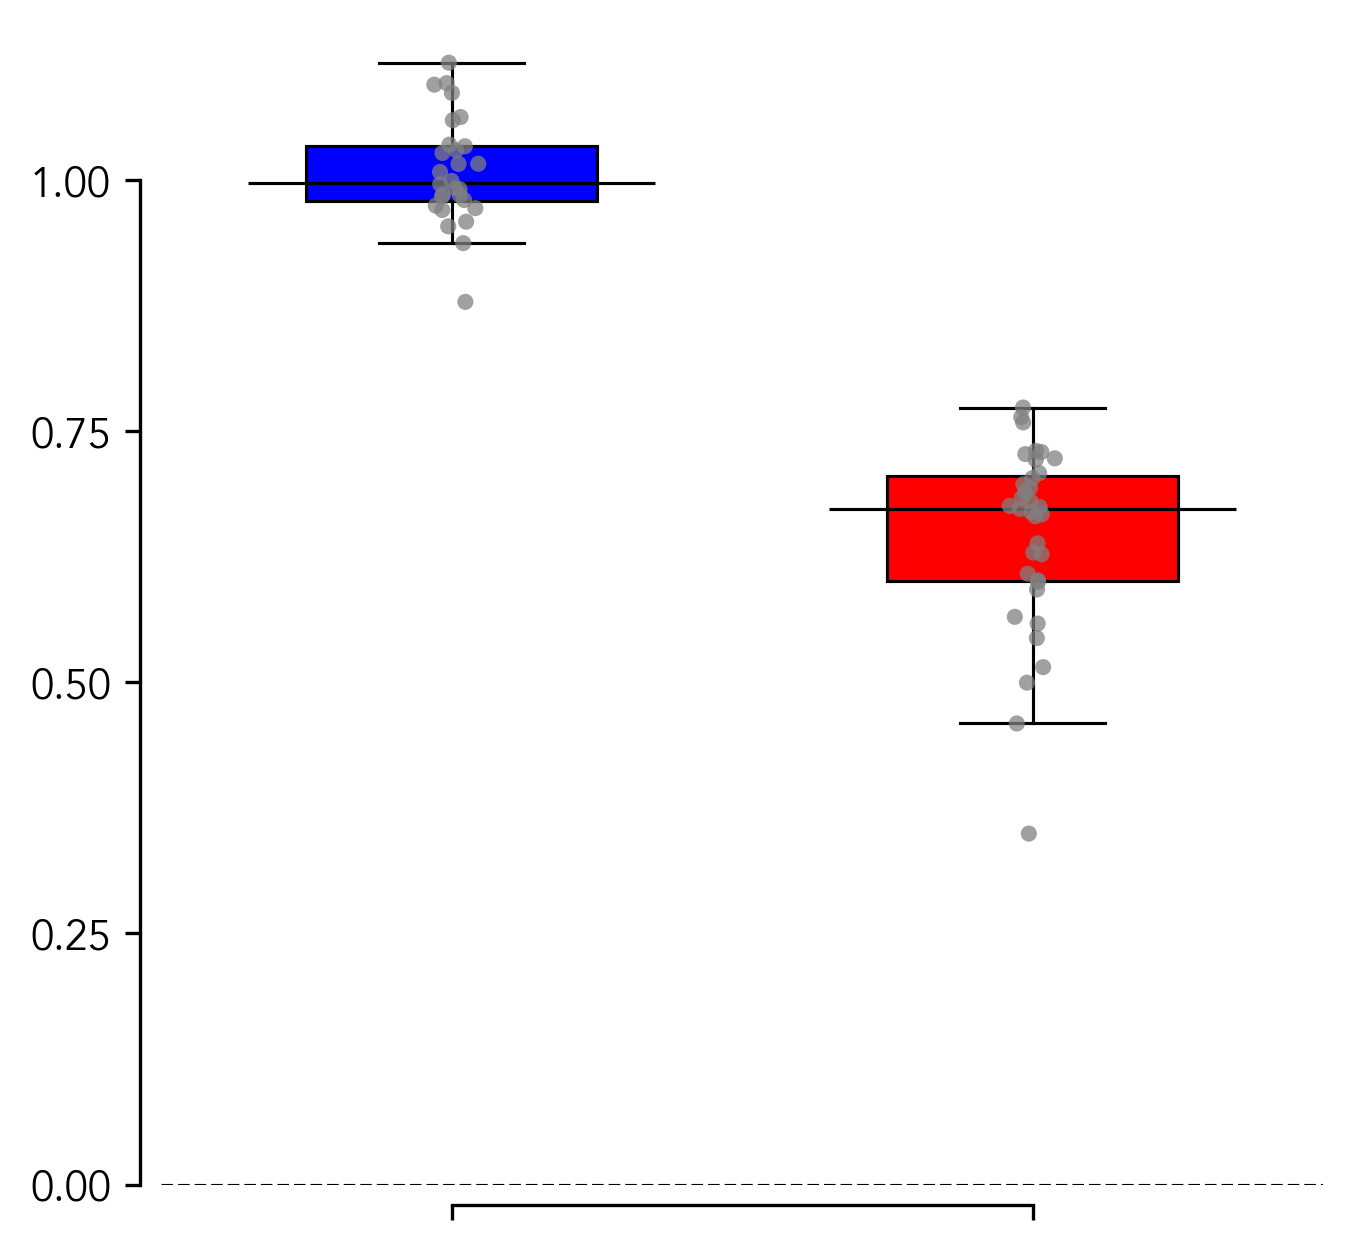

In [47]:
savefig = False

plot_dir = f'{PLOTS_DIR}/fig3'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_pearsonr' # 'pearsonr'

for froi in frois:
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.01 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.75 # 0.5
    markersize = 15 # 25

    bar_positions = np.array([0, 0.5])

    # y=0 line
    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    # Box plot
    box_data = [hh_medians, mh_medians]
    linewidth = 0.75
    barwidth = 0.25 # 0.35
    boxes = plt.boxplot(
                box_data, positions=bar_positions, patch_artist=True, 
                widths=barwidth, showfliers=False,
                boxprops={'color': 'black', 'linewidth': linewidth},
                whiskerprops=dict(linewidth=linewidth),
                capprops=dict(linewidth=linewidth),
                medianprops={'color': 'black', 'linewidth': linewidth},
                flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
            )
    for i, data in enumerate(box_data):
        med = np.median(data)
        # Manually draw a longer median line
        x = bar_positions[i]  # X-position of the boxplot
        # 0.225
        plt.plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
    
    # Color the boxes according to category colors
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    plt.scatter(
        x_subjectsubject, hh_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    plt.xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    plt.ylim(0, 1.15)
    plt.gca().spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    plt.xlim(bar_positions[0]-0.25, bar_positions[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/fig3_univariate_{froi}.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()
    # break  # Only process the first froi for now

### strip plot

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 22.58, p-value: 1.06e-28
plotted


/tmp/ipykernel_3474812/743167082.py:79: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "k." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(
/tmp/ipykernel_3474812/743167082.py:79: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  plt.plot(
/tmp/ipykernel_3474812/743167082.py:83: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "k." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(
/tmp/ipykernel_3474812/743167082.py:83: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  plt.plot(


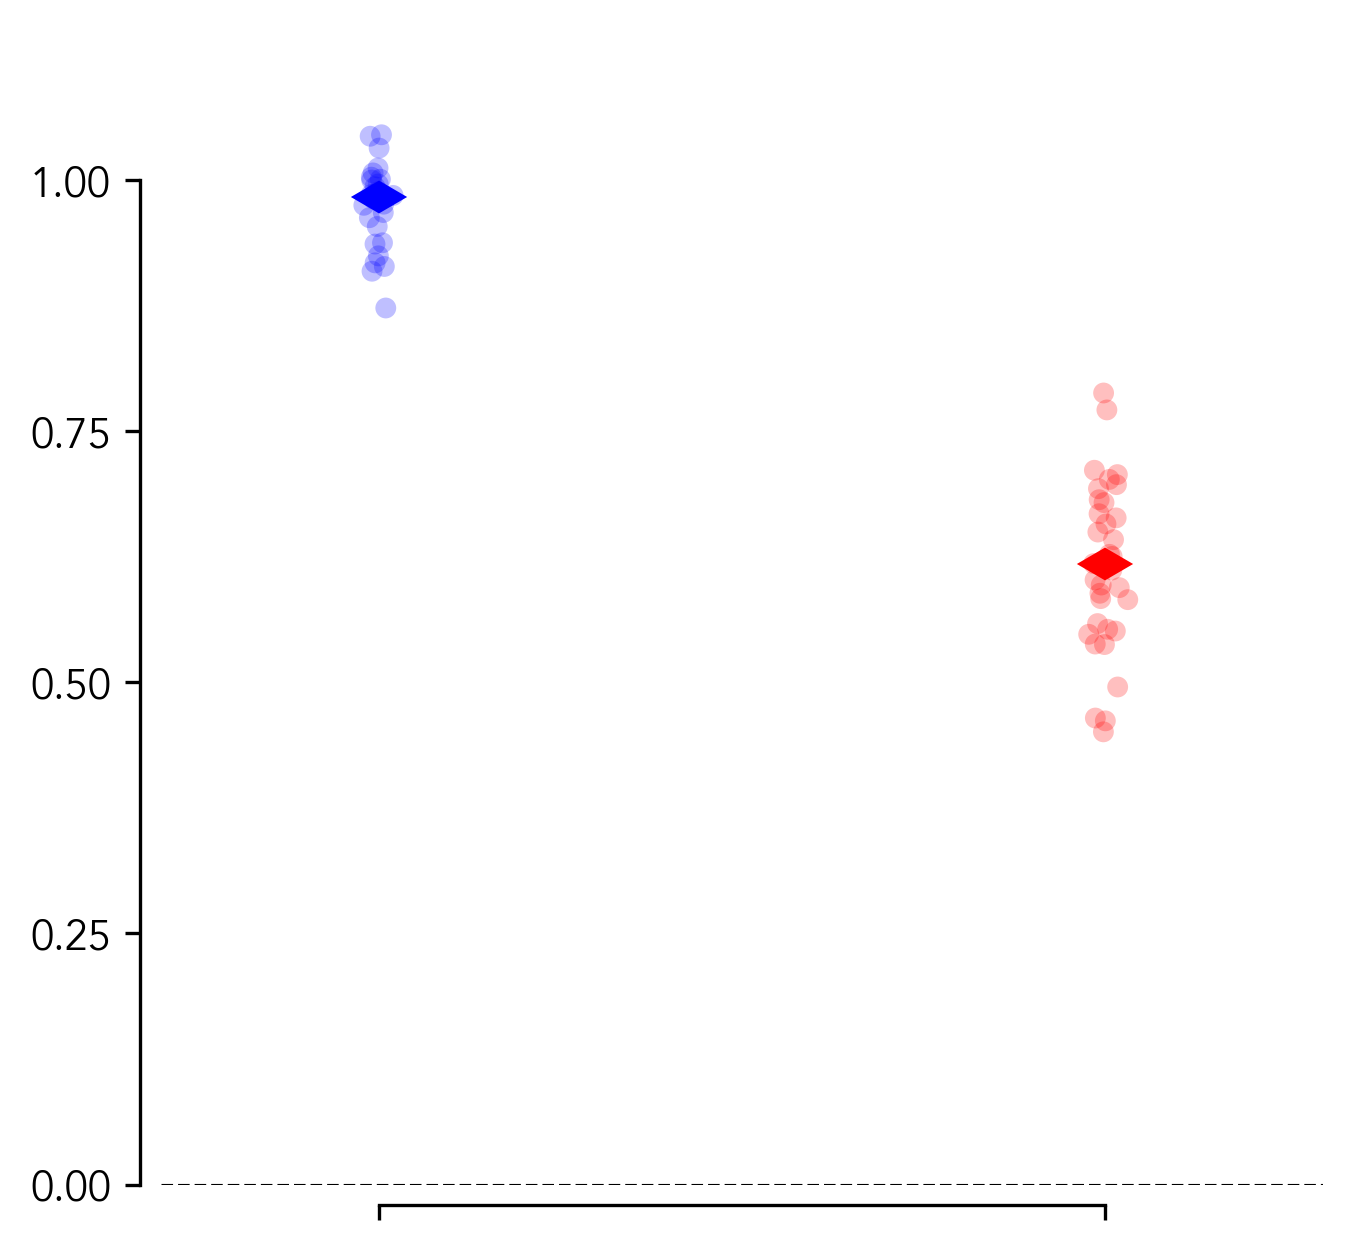

In [10]:
savefig = False

plot_dir = f'{PLOTS_DIR}/fig3'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_pearsonr' # 'pearsonr'

for froi in frois:
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.005 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.25 # 0.5
    markersize = 25 # 25

    bar_positions = np.array([0, 0.5]) # 0, 0.5

    # y=0 line
    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')

    # Create a rotated triangle marker
    import matplotlib.markers as mmarkers
    base_marker = mmarkers.MarkerStyle('d')  # upward triangle
    rotated_marker = mmarkers.MarkerStyle(base_marker)
    rotated_marker._transform = rotated_marker.get_transform().rotate_deg(90)  # rotate 90 deg

    bigmarkersize = 8 # 8
    plt.plot(
        bar_positions[0], [np.median(hh_medians)], 'k.',
        marker=rotated_marker, zorder=10, markersize=bigmarkersize, color=hh_color
    )
    plt.plot(
        bar_positions[1], [np.median(mh_medians)], 'k.',
        marker=rotated_marker, zorder=10, markersize=bigmarkersize, color=mh_color
    )
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    plt.xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    plt.ylim(0, 1.15)
    plt.gca().spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    x_lim_pad = 0.15 # 0.25
    plt.xlim(bar_positions[0]-x_lim_pad, bar_positions[1]+x_lim_pad) 
    plt.tick_params(axis='x', labelbottom=False)
    print('plotted')

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/fig3_univariate_{froi}.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()
    break  # Only process the first froi for now

## Univariate pearson correlations: Individual fROIs

### Bar plots

In [7]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig3/barplots/individual_frois'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'

metric = 'normed_pearsonr' # 'pearsonr'

for froi in frois:
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.01 #0.05
    scatter_pad = -0.05
    alpha = 0.5
    markersize = 25

    x = np.array([0, 0.3])

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*x[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    # plt.errorbar(
    #     x_modelsubject, mh_medians, yerr=mh_sems, fmt='o', ecolor='k', \
    #     capsize=0, label='Model-Subject', markerfacecolor=mh_color, markeredgecolor=mh_color, \
    #     zorder=1, alpha=0.5
    # )
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    # print(hh_medians)
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    # Bar plot with median and SEM
    bar_width = 0.2 #0.4
    medians = [np.median(hh_medians), np.median(mh_medians)]
    sems = [hh_medians.std() / np.sqrt(len(hh_medians)), mh_medians.std() / np.sqrt(len(mh_medians))]

    plt.bar(x, medians, yerr=sems, width=bar_width, color=['blue', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    # plt.text(0.95, 0.89,
    #          f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
    #          horizontalalignment='right', verticalalignment='bottom',
    #          transform=plt.gca().transAxes)
    # plt.xticks(
    #     x, [f'Subject-Subject\nN={len(subjects)+1}*({len(subjects)+1}-1)', 
    #                 f'Model-Subject\nN={len(models)}']
    # )
    plt.xticks(x)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
    # plt.gca().spines['top'].set_visible(False)
    # plt.gca().spines['right'].set_visible(False)
    # plt.ylabel(r'Normalized pearson $\rho$')
    # plt.title(f'Univariate Comparison: {froi}')
    # plt.yticks(np.arange(0, 1.01, 0.2))
    # plt.xlim(-0.5, 1.5)
    # plt.ylim(0, 1.25)

    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1, zorder=0)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    plt.ylim(0, 1.15)
    plt.gca().spines['bottom'].set_bounds(x[0], x[1])
    plt.xlim(x[0]-0.25, x[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/fig3_barplot_univariate_{froi}.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 22.58, p-value: 1.06e-28
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 21.38, p-value: 1.73e-29
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 19.57, p-value: 1.19e-26


### Box plots

In [8]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig3/boxplots/individual_frois'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_pearsonr' # 'pearsonr'

for froi in frois:
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.01 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.75 # 0.5
    markersize = 15 # 25

    bar_positions = np.array([0, 0.5])

    # y=0 line
    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    # Box plot
    box_data = [hh_medians, mh_medians]
    linewidth = 0.75
    barwidth = 0.25 # 0.35
    boxes = plt.boxplot(
                box_data, positions=bar_positions, patch_artist=True, 
                widths=barwidth, showfliers=False,
                boxprops={'color': 'black', 'linewidth': linewidth},
                whiskerprops=dict(linewidth=linewidth),
                capprops=dict(linewidth=linewidth),
                medianprops={'color': 'black', 'linewidth': linewidth},
                flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
            )
    for i, data in enumerate(box_data):
        med = np.median(data)
        # Manually draw a longer median line
        x = bar_positions[i]  # X-position of the boxplot
        # 0.225
        plt.plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
    
    # Color the boxes according to category colors
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    plt.scatter(
        x_subjectsubject, hh_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    plt.xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    plt.ylim(0, 1.15)
    plt.gca().spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    plt.xlim(bar_positions[0]-0.25, bar_positions[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/fig3_boxplot_univariate_{froi}.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 22.58, p-value: 1.06e-28
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 21.38, p-value: 1.73e-29
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 19.57, p-value: 1.19e-26


### Strip plot

In [9]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig3/stripplots/individual_frois'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_pearsonr' # 'pearsonr'

for froi in frois:
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.005 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.25 # 0.5
    markersize = 25 # 25

    bar_positions = np.array([0, 0.5]) # 0, 0.5

    # y=0 line
    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')

    # Create a rotated triangle marker
    base_marker = mmarkers.MarkerStyle('d')  # upward triangle
    rotated_marker = mmarkers.MarkerStyle(base_marker)
    rotated_marker._transform = rotated_marker.get_transform().rotate_deg(90)  # rotate 90 deg

    bigmarkersize = 8 # 8
    plt.plot(
        bar_positions[0], [np.median(hh_medians)], 'k.',
        marker=rotated_marker, zorder=10, markersize=bigmarkersize, color=hh_color
    )
    plt.plot(
        bar_positions[1], [np.median(mh_medians)], 'k.',
        marker=rotated_marker, zorder=10, markersize=bigmarkersize, color=mh_color
    )
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    plt.xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    plt.ylim(0, 1.15)
    plt.gca().spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    x_lim_pad = 0.15 # 0.25
    plt.xlim(bar_positions[0]-x_lim_pad, bar_positions[1]+x_lim_pad) 
    plt.tick_params(axis='x', labelbottom=False)
    print('plotted')

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/fig3_stripplot_univariate_{froi}.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 22.58, p-value: 1.06e-28
plotted
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 21.38, p-value: 1.73e-29
plotted


/tmp/ipykernel_435881/3067541525.py:78: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "k." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(
/tmp/ipykernel_435881/3067541525.py:78: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  plt.plot(
/tmp/ipykernel_435881/3067541525.py:82: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "k." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(
/tmp/ipykernel_435881/3067541525.py:82: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  plt.plot(


EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 19.57, p-value: 1.19e-26
plotted


## Univariate pearson correlations: Subplots

### Box plots

In [ ]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig3/boxplots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_pearsonr' # 'pearsonr'

# fig, ax = plt.figure(figsize=(5, 5), dpi=300)
fig, axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)

for fidx, froi in enumerate(frois):
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    jitter_scale = 0.01 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.75 # 0.5
    markersize = 15 # 25

    bar_positions = np.array([0, 0.5])

    # y=0 line
    axs[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    # Box plot
    box_data = [hh_medians, mh_medians]
    linewidth = 0.75
    barwidth = 0.25 # 0.35
    boxes = axs[fidx].boxplot(
                box_data, positions=bar_positions, patch_artist=True, 
                widths=barwidth, showfliers=False,
                boxprops={'color': 'black', 'linewidth': linewidth},
                whiskerprops=dict(linewidth=linewidth),
                capprops=dict(linewidth=linewidth),
                medianprops={'color': 'black', 'linewidth': linewidth},
                flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
            )
    for i, data in enumerate(box_data):
        med = np.median(data)
        # Manually draw a longer median line
        x = bar_positions[i]  # X-position of the boxplot
        # 0.225
        axs[fidx].plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
    
    # Color the boxes according to category colors
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    axs[fidx].scatter(
        x_subjectsubject, hh_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    axs[fidx].scatter(
        x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    axs[fidx].set_xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
    
    # Write froi name in bottom left corner
    axs[fidx].text(0.05, 0.25, froi, transform=axs[fidx].transAxes, fontsize=12, verticalalignment='top')

    axs[fidx].spines['top'].set_visible(False)
    axs[fidx].spines['right'].set_visible(False)
    axs[fidx].spines['left'].set_position(('outward', 5))
    axs[fidx].spines['bottom'].set_position(('outward', 5))
    axs[fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
    axs[fidx].spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    axs[fidx].set_ylim(0, 1.15)
    axs[fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    axs[fidx].set_xlim(bar_positions[0]-0.25, bar_positions[1]+0.25)
    axs[fidx].tick_params(axis='x', labelbottom=False)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

if savefig:
    plt.savefig(f'{plot_dir}/fig3b_boxplot_univariate.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 22.58, p-value: 1.06e-28
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 21.38, p-value: 1.73e-29
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 19.57, p-value: 1.19e-26


### Strip plots

In [4]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig3/stripplots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_pearsonr' # 'pearsonr'

fig, axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)

for fidx, froi in enumerate(frois):
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    jitter_scale = 0.005 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.25 # 0.5
    markersize = 25 # 25

    bar_positions = np.array([0, 0.5]) # 0, 0.5

    # y=0 line
    axs[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    axs[fidx].scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    axs[fidx].scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')

    # Create a rotated triangle marker
    base_marker = mmarkers.MarkerStyle('d')  # upward triangle
    rotated_marker = mmarkers.MarkerStyle(base_marker)
    rotated_marker._transform = rotated_marker.get_transform().rotate_deg(90)  # rotate 90 deg

    bigmarkersize = 8 # 8
    axs[fidx].plot(
        bar_positions[0], [np.median(hh_medians)], 'k.',
        marker=rotated_marker, zorder=10, markersize=bigmarkersize, color=hh_color
    )
    axs[fidx].plot(
        bar_positions[1], [np.median(mh_medians)], 'k.',
        marker=rotated_marker, zorder=10, markersize=bigmarkersize, color=mh_color
    )
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    axs[fidx].set_xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    # Write froi name in bottom left corner
    axs[fidx].text(0.05, 0.25, froi, transform=axs[fidx].transAxes, fontsize=12, verticalalignment='top')

    axs[fidx].spines['top'].set_visible(False)
    axs[fidx].spines['right'].set_visible(False)
    axs[fidx].spines['left'].set_position(('outward', 5))
    axs[fidx].spines['bottom'].set_position(('outward', 5))
    axs[fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
    axs[fidx].spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    axs[fidx].set_ylim(0, 1.15)
    axs[fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    x_lim_pad = 0.15 # 0.25
    axs[fidx].set_xlim(bar_positions[0]-x_lim_pad, bar_positions[1]+x_lim_pad) 
    axs[fidx].tick_params(axis='x', labelbottom=False)
    print('plotted')

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

if savefig:
    plt.savefig(f'{plot_dir}/fig3b_stripplot_univariate.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 22.58, p-value: 1.06e-28
plotted
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 21.38, p-value: 1.73e-29
plotted
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 19.57, p-value: 1.19e-26
plotted


/tmp/ipykernel_717823/2023554278.py:79: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "k." (-> marker='.'). The keyword argument will take precedence.
  axs[fidx].plot(
/tmp/ipykernel_717823/2023554278.py:79: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  axs[fidx].plot(
/tmp/ipykernel_717823/2023554278.py:83: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "k." (-> marker='.'). The keyword argument will take precedence.
  axs[fidx].plot(
/tmp/ipykernel_717823/2023554278.py:83: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  axs[fidx].plot(


## Multivariate RDM correlations: Individual fROIs

### Bar plots

In [15]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig3/barplots/individual_frois'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'

metric = 'normed_rdmr' # 'pearsonr'

for froi in frois:
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.01 #0.05
    scatter_pad = -0.05
    alpha = 0.5
    markersize = 25

    x = np.array([0, 0.3])

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*x[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    # plt.errorbar(
    #     x_modelsubject, mh_medians, yerr=mh_sems, fmt='o', ecolor='k', \
    #     capsize=0, label='Model-Subject', markerfacecolor=mh_color, markeredgecolor=mh_color, \
    #     zorder=1, alpha=0.5
    # )
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    # print(hh_medians)
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    # Bar plot with median and SEM
    bar_width = 0.2 #0.4
    medians = [np.median(hh_medians), np.median(mh_medians)]
    sems = [hh_medians.std() / np.sqrt(len(hh_medians)), mh_medians.std() / np.sqrt(len(mh_medians))]

    plt.bar(x, medians, yerr=sems, width=bar_width, color=['blue', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    # plt.text(0.95, 0.89,
    #          f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
    #          horizontalalignment='right', verticalalignment='bottom',
    #          transform=plt.gca().transAxes)
    # plt.xticks(
    #     x, [f'Subject-Subject\nN={len(subjects)+1}*({len(subjects)+1}-1)', 
    #                 f'Model-Subject\nN={len(models)}']
    # )
    plt.xticks(x)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
    # plt.gca().spines['top'].set_visible(False)
    # plt.gca().spines['right'].set_visible(False)
    # plt.ylabel(r'Normalized pearson $\rho$')
    # plt.title(f'Univariate Comparison: {froi}')
    # plt.yticks(np.arange(0, 1.01, 0.2))
    # plt.xlim(-0.5, 1.5)
    # plt.ylim(0, 1.25)

    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1, zorder=0)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    plt.ylim(0, 1.4)
    plt.gca().spines['bottom'].set_bounds(x[0], x[1])
    plt.xlim(x[0]-0.25, x[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/fig3_barplot_multivariate_{froi}.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.32, p-value: 7.28e-32
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.95, p-value: 6.78e-29
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 28.25, p-value: 9.86e-37


### Box plots

In [16]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig3/boxplots/individual_frois'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_rdmr' # 'pearsonr'

for froi in frois:
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.01 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.75 # 0.5
    markersize = 15 # 25

    bar_positions = np.array([0, 0.5])

    # y=0 line
    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    # Box plot
    box_data = [hh_medians, mh_medians]
    linewidth = 0.75
    barwidth = 0.25 # 0.35
    boxes = plt.boxplot(
                box_data, positions=bar_positions, patch_artist=True, 
                widths=barwidth, showfliers=False,
                boxprops={'color': 'black', 'linewidth': linewidth},
                whiskerprops=dict(linewidth=linewidth),
                capprops=dict(linewidth=linewidth),
                medianprops={'color': 'black', 'linewidth': linewidth},
                flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
            )
    for i, data in enumerate(box_data):
        med = np.median(data)
        # Manually draw a longer median line
        x = bar_positions[i]  # X-position of the boxplot
        # 0.225
        plt.plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
    
    # Color the boxes according to category colors
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    plt.scatter(
        x_subjectsubject, hh_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    # print(hh_medians)
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    plt.xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    plt.ylim(0, 1.4)
    plt.gca().spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    plt.xlim(bar_positions[0]-0.25, bar_positions[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/fig3_boxplot_multivariate_{froi}.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.32, p-value: 7.28e-32
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.95, p-value: 6.78e-29
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 28.25, p-value: 9.86e-37


### Strip plots

In [17]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig3/stripplots/individual_frois'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_rdmr' # 'pearsonr'

for froi in frois:
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.005 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.25 # 0.5
    markersize = 25 # 25

    bar_positions = np.array([0, 0.5]) # 0, 0.5

    # y=0 line
    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')

    # Create a rotated triangle marker
    base_marker = mmarkers.MarkerStyle('d')  # upward triangle
    rotated_marker = mmarkers.MarkerStyle(base_marker)
    rotated_marker._transform = rotated_marker.get_transform().rotate_deg(90)  # rotate 90 deg

    bigmarkersize = 8 # 8
    plt.plot(
        bar_positions[0], [np.median(hh_medians)], 'k.',
        marker=rotated_marker, zorder=10, markersize=bigmarkersize, color=hh_color
    )
    plt.plot(
        bar_positions[1], [np.median(mh_medians)], 'k.',
        marker=rotated_marker, zorder=10, markersize=bigmarkersize, color=mh_color
    )
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    plt.xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    plt.ylim(0, 1.4)
    plt.gca().spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    x_lim_pad = 0.15 # 0.25
    plt.xlim(bar_positions[0]-x_lim_pad, bar_positions[1]+x_lim_pad) 
    plt.tick_params(axis='x', labelbottom=False)
    print('plotted')

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/fig3_stripplot_multivariate_{froi}.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.32, p-value: 7.28e-32
plotted
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.95, p-value: 6.78e-29
plotted


/tmp/ipykernel_435881/1773550072.py:78: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "k." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(
/tmp/ipykernel_435881/1773550072.py:78: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  plt.plot(
/tmp/ipykernel_435881/1773550072.py:82: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "k." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(
/tmp/ipykernel_435881/1773550072.py:82: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  plt.plot(


EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 28.25, p-value: 9.86e-37
plotted


## Multivariate RDM correlations: Subplots

### Box plots

In [5]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig3/boxplots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_rdmr' # 'pearsonr'

fig, axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)

for fidx, froi in enumerate(frois):
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    jitter_scale = 0.01 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.75 # 0.5
    markersize = 15 # 25

    bar_positions = np.array([0, 0.5])

    # y=0 line
    axs[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    # Box plot
    box_data = [hh_medians, mh_medians]
    linewidth = 0.75
    barwidth = 0.25 # 0.35
    boxes = axs[fidx].boxplot(
                box_data, positions=bar_positions, patch_artist=True, 
                widths=barwidth, showfliers=False,
                boxprops={'color': 'black', 'linewidth': linewidth},
                whiskerprops=dict(linewidth=linewidth),
                capprops=dict(linewidth=linewidth),
                medianprops={'color': 'black', 'linewidth': linewidth},
                flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
            )
    for i, data in enumerate(box_data):
        med = np.median(data)
        # Manually draw a longer median line
        x = bar_positions[i]  # X-position of the boxplot
        # 0.225
        axs[fidx].plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
    
    # Color the boxes according to category colors
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    axs[fidx].scatter(
        x_subjectsubject, hh_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    axs[fidx].scatter(
        x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    # print(hh_medians)
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    axs[fidx].set_xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    # Write froi name in bottom left corner
    axs[fidx].text(0.05, 0.25, froi, transform=axs[fidx].transAxes, fontsize=12, verticalalignment='top')

    axs[fidx].spines['top'].set_visible(False)
    axs[fidx].spines['right'].set_visible(False)
    axs[fidx].spines['left'].set_position(('outward', 5))
    axs[fidx].spines['bottom'].set_position(('outward', 5))
    axs[fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
    axs[fidx].spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    axs[fidx].set_ylim(0, 1.4)
    axs[fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    axs[fidx].set_xlim(bar_positions[0]-0.25, bar_positions[1]+0.25)
    axs[fidx].tick_params(axis='x', labelbottom=False)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

if savefig:
    plt.savefig(f'{plot_dir}/fig3d_boxplot_multivariate.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()


FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.32, p-value: 7.28e-32
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.95, p-value: 6.78e-29
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 28.25, p-value: 9.86e-37


### Strip plots

In [ ]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig3/stripplots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_rdmr' # 'pearsonr'

fig, axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)

for fidx, froi in enumerate(frois):
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    jitter_scale = 0.005 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.25 # 0.5
    markersize = 25 # 25

    bar_positions = np.array([0, 0.5]) # 0, 0.5

    # y=0 line
    axs[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    axs[fidx].scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    axs[fidx].scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')

    # Create a rotated triangle marker
    base_marker = mmarkers.MarkerStyle('d')  # upward triangle
    rotated_marker = mmarkers.MarkerStyle(base_marker)
    rotated_marker._transform = rotated_marker.get_transform().rotate_deg(90)  # rotate 90 deg

    bigmarkersize = 8 # 8
    axs[fidx].plot(
        bar_positions[0], [np.median(hh_medians)], 'k.',
        marker=rotated_marker, zorder=10, markersize=bigmarkersize, color=hh_color
    )
    axs[fidx].plot(
        bar_positions[1], [np.median(mh_medians)], 'k.',
        marker=rotated_marker, zorder=10, markersize=bigmarkersize, color=mh_color
    )
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    axs[fidx].set_xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    # Write froi name in bottom left corner
    axs[fidx].text(0.05, 0.25, froi, transform=axs[fidx].transAxes, fontsize=12, verticalalignment='top')

    axs[fidx].spines['top'].set_visible(False)
    axs[fidx].spines['right'].set_visible(False)
    axs[fidx].spines['left'].set_position(('outward', 5))
    axs[fidx].spines['bottom'].set_position(('outward', 5))
    axs[fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
    axs[fidx].spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    axs[fidx].set_ylim(0, 1.4)
    axs[fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    x_lim_pad = 0.15 # 0.25
    axs[fidx].set_xlim(bar_positions[0]-x_lim_pad, bar_positions[1]+x_lim_pad) 
    axs[fidx].tick_params(axis='x', labelbottom=False)
    print('plotted')

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

if savefig:
    plt.savefig(f'{plot_dir}/fig3d_stripplot_multivariate.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.32, p-value: 7.28e-32
plotted
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.95, p-value: 6.78e-29
plotted
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 28.25, p-value: 9.86e-37
plotted


/tmp/ipykernel_717823/676335083.py:79: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "k." (-> marker='.'). The keyword argument will take precedence.
  axs[fidx].plot(
/tmp/ipykernel_717823/676335083.py:79: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  axs[fidx].plot(
/tmp/ipykernel_717823/676335083.py:83: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "k." (-> marker='.'). The keyword argument will take precedence.
  axs[fidx].plot(
/tmp/ipykernel_717823/676335083.py:83: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  axs[fidx].plot(


## Sup: froi-froi correlations (Boxplots)

### Univariate

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
Number of FROI-OFA correlations: 56
Number of FROI-EBA correlations: 56
Number of FROI-PPA correlations: 56
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
Number of FROI-FBA correlations: 56
Number of FROI-FFA correlations: 56
Number of FROI-PPA correlations: 56
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
Number of FROI-OPA correlations: 56
Number of FROI-RSC correlations: 56
Number of FROI-FFA correlations: 56


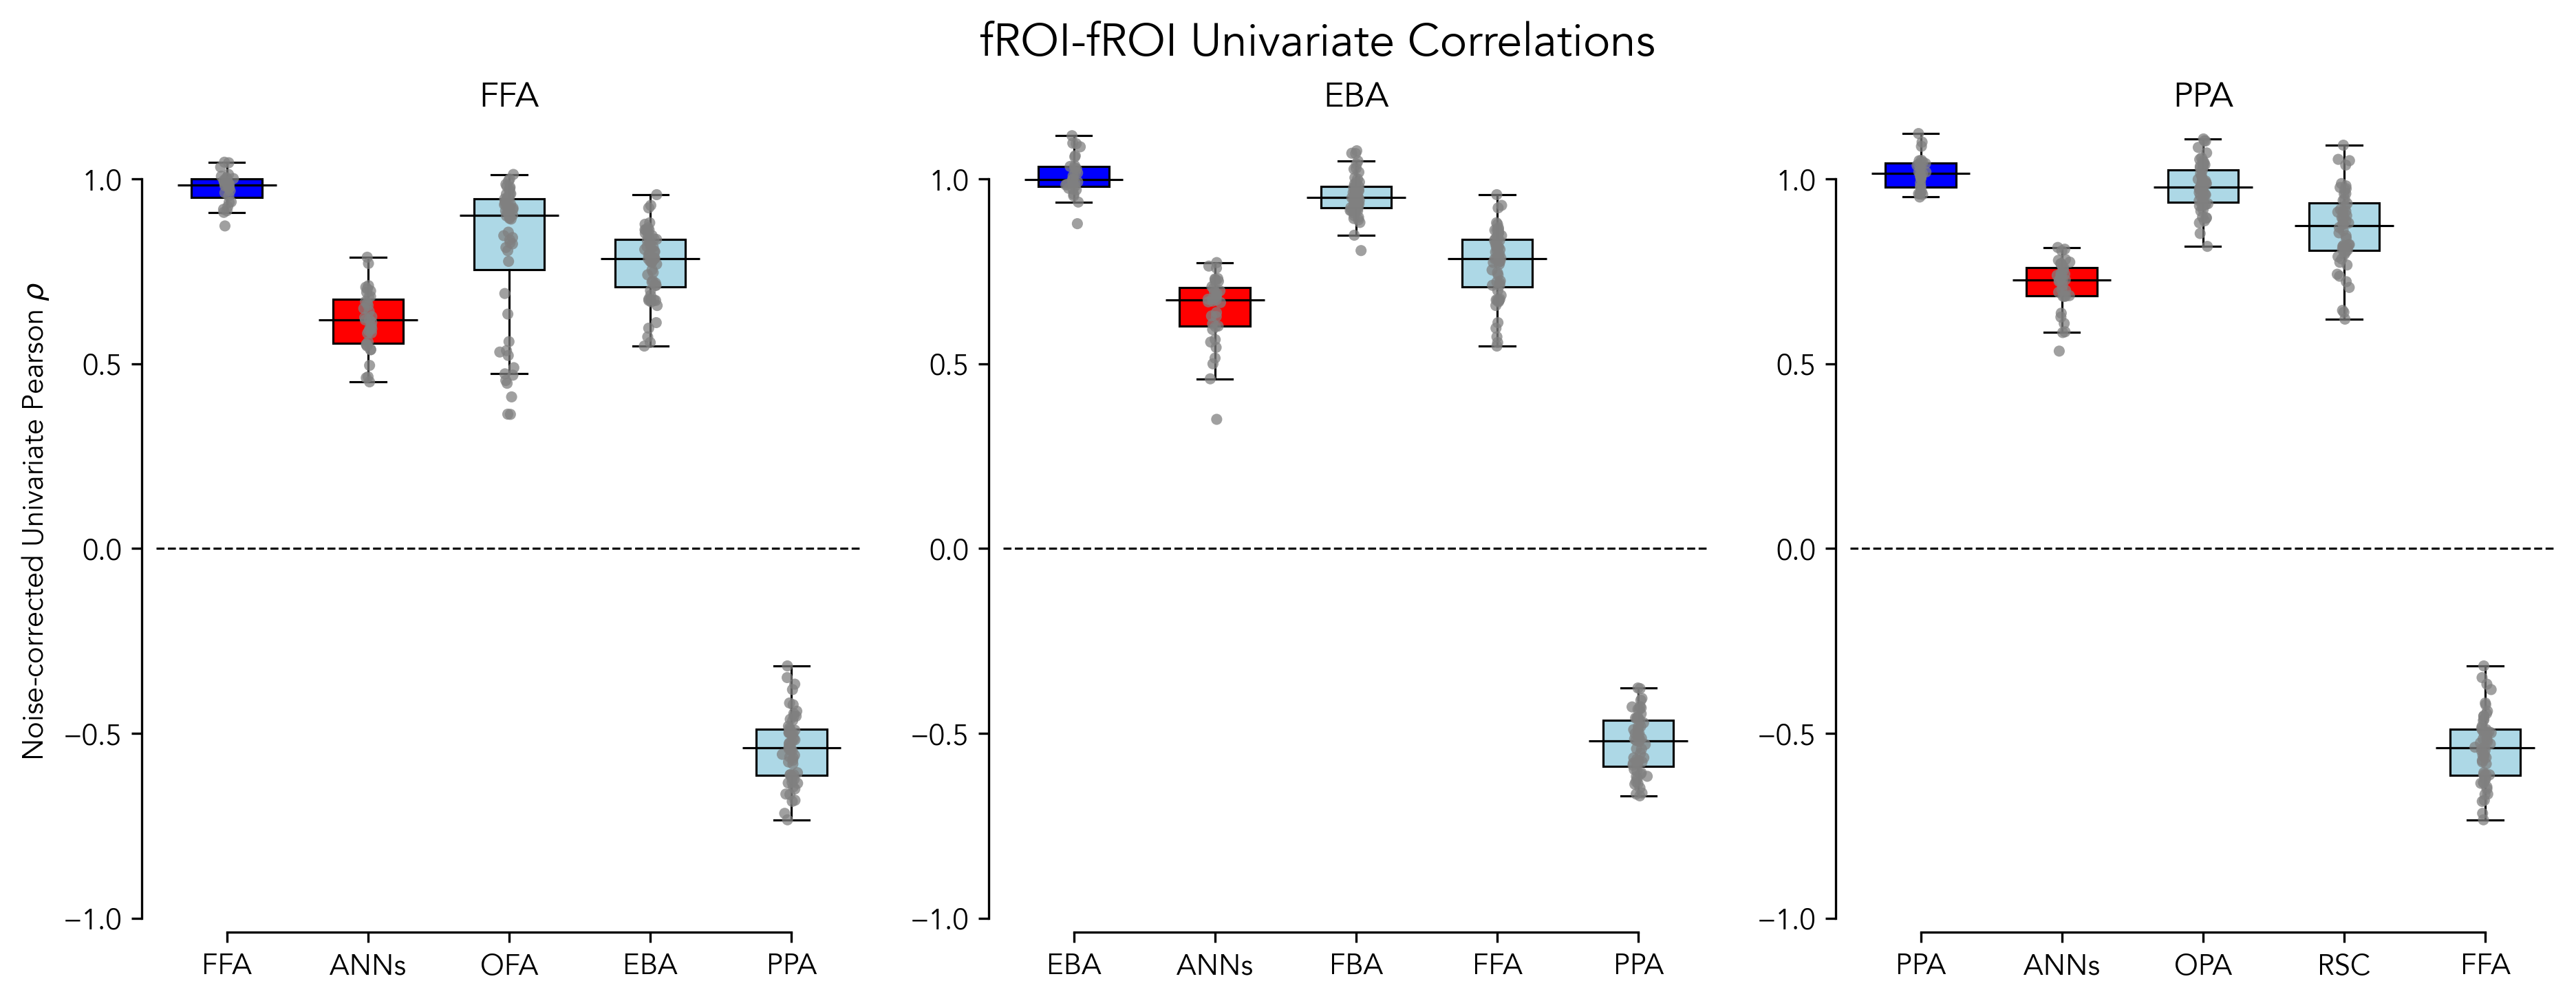

In [47]:
savefig = False

plot_dir = f'{PLOTS_DIR}/fig3/supplementary'
os.makedirs(plot_dir, exist_ok=True)

froifroi_correlations_csv = pd.read_csv(FROIFROI_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
probe_frois = list(froi_comparisons.keys())
subjects = froifroi_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

ff_color = 'blue'
mh_color = 'red'
ff2_color = 'lightblue' # Light blue
colors = [ff_color, mh_color, ff2_color, ff2_color, ff2_color]

metric = 'normed_pearsonr' # 'pearsonr'

fig, axs = plt.subplots(1, len(probe_frois), figsize=(5*len(probe_frois), 5), dpi=300)

for fidx, froi in enumerate(probe_frois):
    print(froi)
    ff_medians = []
    sbjsbj_pairs = []
    for sbjidx1, sbj1 in enumerate(subjects):
        for sbjidx2, sbj2 in enumerate(subjects[sbjidx1+1:]):
            sbjsbj_pairs.append((sbj1, sbj2))

    for sbjpair in sbjsbj_pairs:
        subject1, subject2 = sbjpair
        subjectsubject_froi = froifroi_correlations_csv[
            (froifroi_correlations_csv['fmri_froi1'] == froi) &
            (froifroi_correlations_csv['fmri_froi2'] == froi) &
            (froifroi_correlations_csv['subject1'] == subject1) &
            (froifroi_correlations_csv['subject2'] == subject2) &
            (froifroi_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        ff_medians += list(subjectsubject_froi[metric])
    ff_medians = np.array(ff_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in taskoptimized_model_names:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    ff2_medians = {}
    other_frois = froi_comparisons[froi]
    for other_froi in other_frois:
        otherfroifroi_medians = []
        subjectsubject_otherfroi = froifroi_correlations_csv[
            (froifroi_correlations_csv['fmri_froi1'] == froi) &
            (froifroi_correlations_csv['fmri_froi2'] == other_froi) &
            (froifroi_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        if len(subjectsubject_otherfroi) == 0:
            subjectsubject_otherfroi = froifroi_correlations_csv[
                (froifroi_correlations_csv['fmri_froi2'] == froi) &
                (froifroi_correlations_csv['fmri_froi1'] == other_froi) &
                (froifroi_correlations_csv['fmri_tthreshold'] == tthreshold)
            ]
        otherfroifroi_medians += list(subjectsubject_otherfroi[metric])
        otherfroifroi_medians = np.array(otherfroifroi_medians).flatten()
        ff2_medians[other_froi] = otherfroifroi_medians

    jitter_scale = 0.01 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.75 # 0.5
    markersize = 15 # 25

    bar_positions = np.array([0, 0.5, 1, 1.5, 2])  # Adjusted for three additional boxes

    # y=0 line
    axs[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    # Box plot
    box_data = [ff_medians, mh_medians] + [ff2_medians[other_froi] for other_froi in other_frois]
    linewidth = 0.75
    barwidth = 0.25 # 0.35
    boxes = axs[fidx].boxplot(
                box_data, positions=bar_positions, patch_artist=True, 
                widths=barwidth, showfliers=False,
                boxprops={'color': 'black', 'linewidth': linewidth},
                whiskerprops=dict(linewidth=linewidth),
                capprops=dict(linewidth=linewidth),
                medianprops={'color': 'black', 'linewidth': linewidth},
                flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
            )
    for i, data in enumerate(box_data):
        med = np.median(data)
        # Manually draw a longer median line
        x = bar_positions[i]  # X-position of the boxplot
        # 0.225
        axs[fidx].plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
    
    # Color the boxes according to category colors
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)

    x_subjectsubject = np.zeros(len(ff_medians)) + np.random.normal(0, jitter_scale, len(ff_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    axs[fidx].scatter(
        x_subjectsubject, ff_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    axs[fidx].scatter(
        x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    for i, other_froi in enumerate(other_frois):
        otherfroifroi_medians = ff2_medians[other_froi]
        x_otherfroifroi = np.ones(len(otherfroifroi_medians))*bar_positions[2 + i] + np.random.normal(0, jitter_scale, len(otherfroifroi_medians))
        x_otherfroifroi += scatter_pad
        axs[fidx].scatter(
            x_otherfroifroi, otherfroifroi_medians, color='gray', alpha=alpha, label=f'FROI-{other_froi}', zorder=5,
            edgecolors='none', s=markersize
        )
    # print(ff_medians)
    print(f'Number of Subject-Subject correlations: {len(ff_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    for other_froi in other_frois:
        print(f'Number of FROI-{other_froi} correlations: {len(ff2_medians[other_froi])}')

    # Conduct Welch's t-test
    # t_value, p_value = scipy.stats.ttest_ind(ff_medians, mh_medians, equal_var=False)
    # axs[fidx].set_xticks(bar_positions)
    # print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    # Write froi name in bottom left corner
    # axs[fidx].text(0.05, 0.25, froi, transform=axs[fidx].transAxes, fontsize=12, verticalalignment='top')

    # Add x-axis labels
    axs[fidx].set_xticks(bar_positions)
    x_labels = [froi, 'ANNs'] + [other_froi for other_froi in other_frois]
    axs[fidx].set_xticklabels(x_labels)

    axs[fidx].spines['top'].set_visible(False)
    axs[fidx].spines['right'].set_visible(False)
    axs[fidx].spines['left'].set_position(('outward', 5))
    axs[fidx].spines['bottom'].set_position(('outward', 5))
    axs[fidx].set_yticks([-1, -0.5, 0, 0.5, 1])
    axs[fidx].spines['left'].set_bounds(-1, 1)
    # plt.tick_params(axis='y', labelleft=False)
    axs[fidx].set_ylim(-1, 1.15)
    axs[fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[-1])
    axs[fidx].set_xlim(bar_positions[0]-0.25, bar_positions[-1]+0.25)
    # axs[fidx].tick_params(axis='x', labelbottom=False)
    axs[fidx].set_title(froi)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])
    if froi == 'FFA':
        axs[fidx].set_ylabel(r'Noise-corrected Univariate Pearson $\rho$')

plt.suptitle('fROI-fROI Univariate Correlations', fontsize=16)

if savefig:
    plt.savefig(f'{plot_dir}/fig3sup_froifroi_univariate.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()


### Mulrivariate RDM

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
Number of FROI-OFA correlations: 56
Number of FROI-EBA correlations: 56
Number of FROI-PPA correlations: 56
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
Number of FROI-FBA correlations: 56
Number of FROI-FFA correlations: 56
Number of FROI-PPA correlations: 56
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
Number of FROI-OPA correlations: 56
Number of FROI-RSC correlations: 56
Number of FROI-FFA correlations: 56


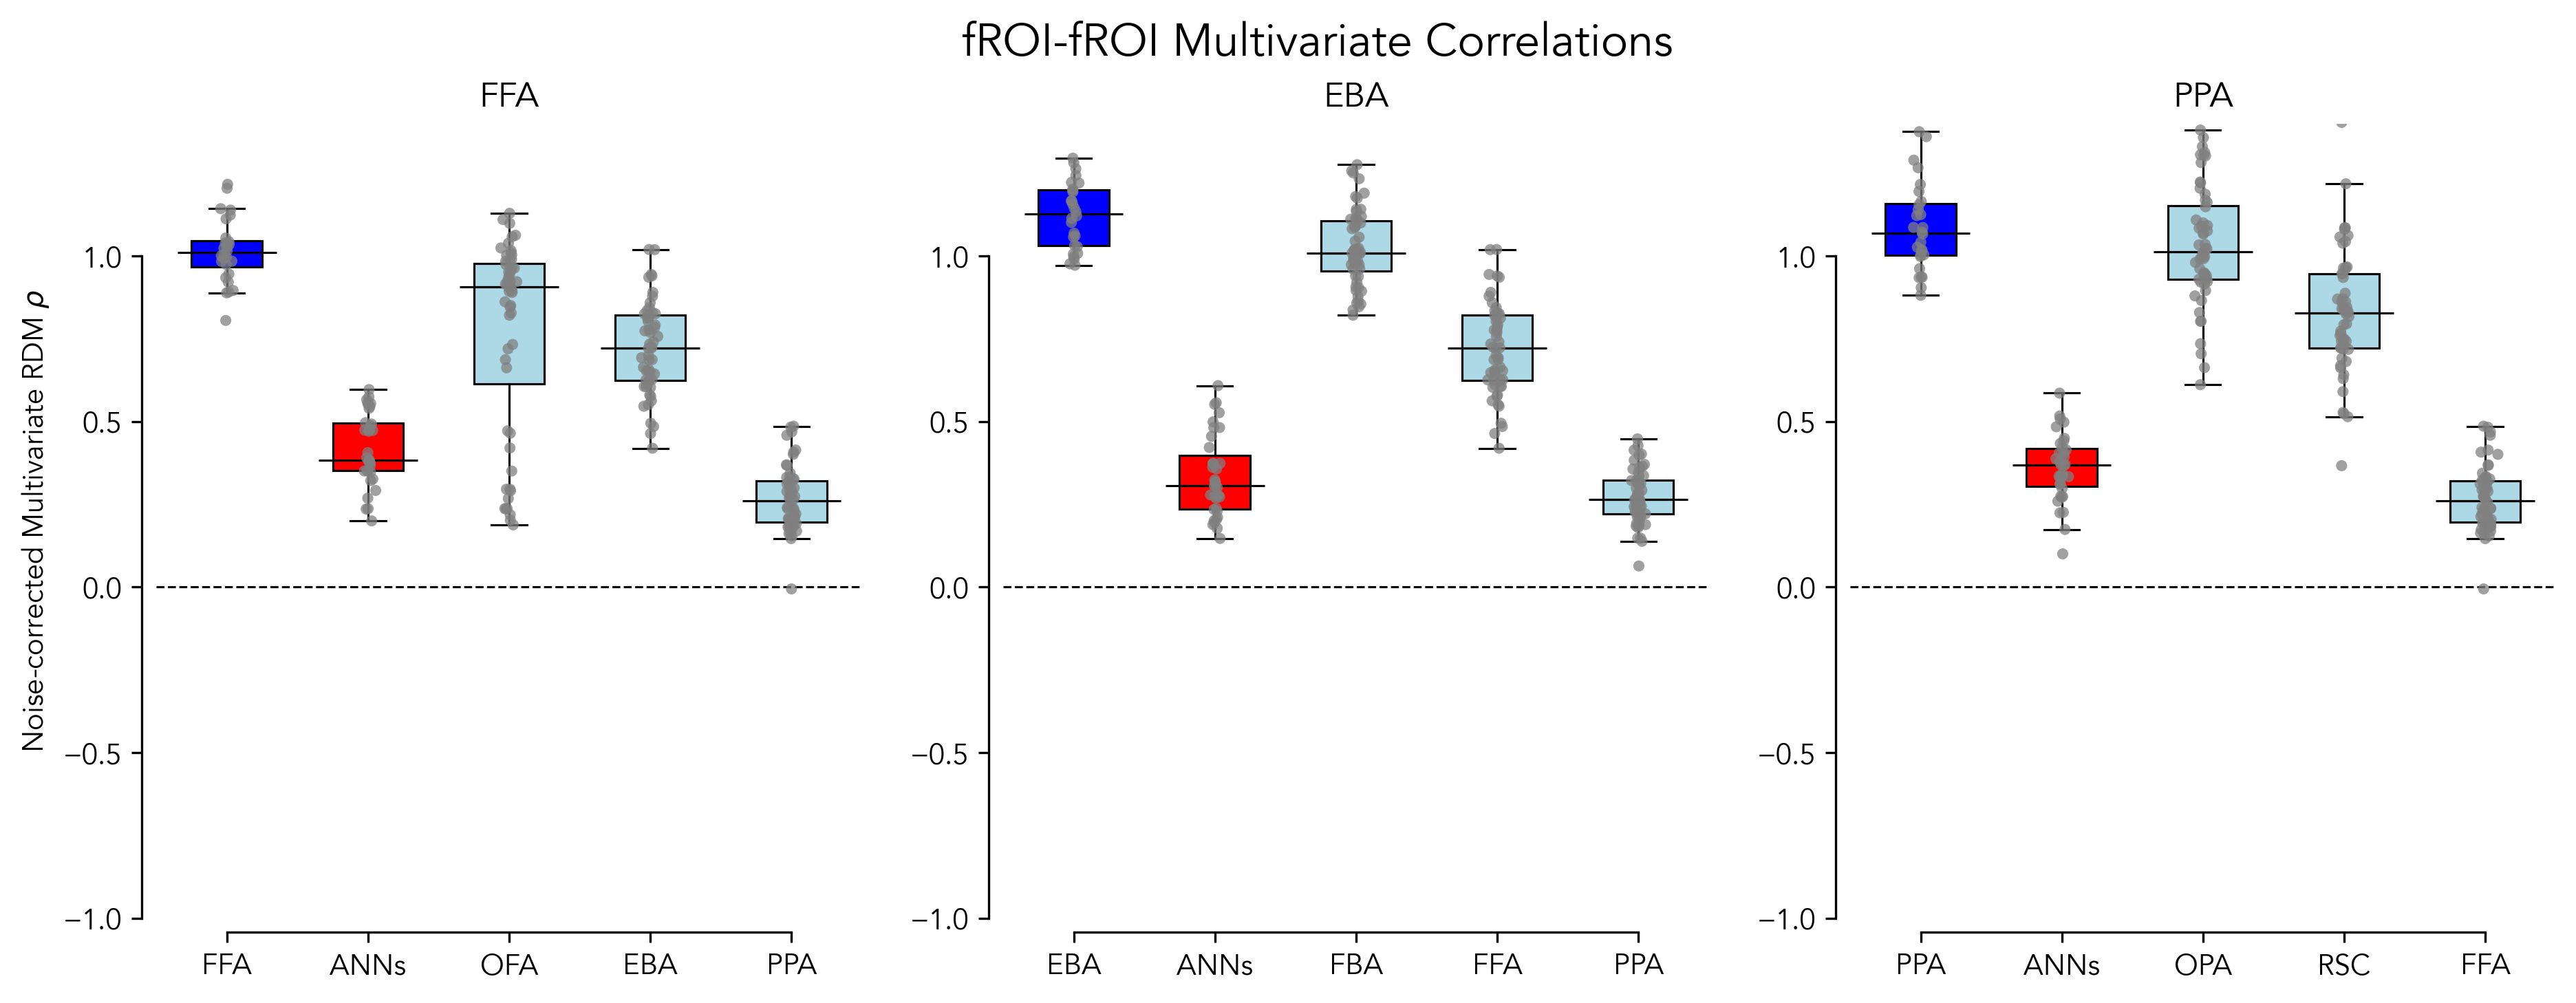

In [48]:
savefig = False

plot_dir = f'{PLOTS_DIR}/fig3/supplementary'
os.makedirs(plot_dir, exist_ok=True)

froifroi_correlations_csv = pd.read_csv(FROIFROI_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
probe_frois = list(froi_comparisons.keys())
subjects = froifroi_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

ff_color = 'blue'
mh_color = 'red'
ff2_color = 'lightblue' # Light blue
colors = [ff_color, mh_color, ff2_color, ff2_color, ff2_color]

metric = 'normed_rdmr' # 'pearsonr'

fig, axs = plt.subplots(1, len(probe_frois), figsize=(5*len(probe_frois), 5), dpi=300)

for fidx, froi in enumerate(probe_frois):
    print(froi)
    ff_medians = []
    sbjsbj_pairs = []
    for sbjidx1, sbj1 in enumerate(subjects):
        for sbjidx2, sbj2 in enumerate(subjects[sbjidx1+1:]):
            sbjsbj_pairs.append((sbj1, sbj2))

    for sbjpair in sbjsbj_pairs:
        subject1, subject2 = sbjpair
        subjectsubject_froi = froifroi_correlations_csv[
            (froifroi_correlations_csv['fmri_froi1'] == froi) &
            (froifroi_correlations_csv['fmri_froi2'] == froi) &
            (froifroi_correlations_csv['subject1'] == subject1) &
            (froifroi_correlations_csv['subject2'] == subject2) &
            (froifroi_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        ff_medians += list(subjectsubject_froi[metric])
    ff_medians = np.array(ff_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in taskoptimized_model_names:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    ff2_medians = {}
    other_frois = froi_comparisons[froi]
    for other_froi in other_frois:
        otherfroifroi_medians = []
        subjectsubject_otherfroi = froifroi_correlations_csv[
            (froifroi_correlations_csv['fmri_froi1'] == froi) &
            (froifroi_correlations_csv['fmri_froi2'] == other_froi) &
            (froifroi_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        if len(subjectsubject_otherfroi) == 0:
            subjectsubject_otherfroi = froifroi_correlations_csv[
                (froifroi_correlations_csv['fmri_froi2'] == froi) &
                (froifroi_correlations_csv['fmri_froi1'] == other_froi) &
                (froifroi_correlations_csv['fmri_tthreshold'] == tthreshold)
            ]
        otherfroifroi_medians += list(subjectsubject_otherfroi[metric])
        otherfroifroi_medians = np.array(otherfroifroi_medians).flatten()
        ff2_medians[other_froi] = otherfroifroi_medians

    jitter_scale = 0.01 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.75 # 0.5
    markersize = 15 # 25

    bar_positions = np.array([0, 0.5, 1, 1.5, 2])  # Adjusted for three additional boxes

    # y=0 line
    axs[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    # Box plot
    box_data = [ff_medians, mh_medians] + [ff2_medians[other_froi] for other_froi in other_frois]
    linewidth = 0.75
    barwidth = 0.25 # 0.35
    boxes = axs[fidx].boxplot(
                box_data, positions=bar_positions, patch_artist=True, 
                widths=barwidth, showfliers=False,
                boxprops={'color': 'black', 'linewidth': linewidth},
                whiskerprops=dict(linewidth=linewidth),
                capprops=dict(linewidth=linewidth),
                medianprops={'color': 'black', 'linewidth': linewidth},
                flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
            )
    for i, data in enumerate(box_data):
        med = np.median(data)
        # Manually draw a longer median line
        x = bar_positions[i]  # X-position of the boxplot
        # 0.225
        axs[fidx].plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
    
    # Color the boxes according to category colors
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)

    x_subjectsubject = np.zeros(len(ff_medians)) + np.random.normal(0, jitter_scale, len(ff_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    axs[fidx].scatter(
        x_subjectsubject, ff_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    axs[fidx].scatter(
        x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    for i, other_froi in enumerate(other_frois):
        otherfroifroi_medians = ff2_medians[other_froi]
        x_otherfroifroi = np.ones(len(otherfroifroi_medians))*bar_positions[2 + i] + np.random.normal(0, jitter_scale, len(otherfroifroi_medians))
        x_otherfroifroi += scatter_pad
        axs[fidx].scatter(
            x_otherfroifroi, otherfroifroi_medians, color='gray', alpha=alpha, label=f'FROI-{other_froi}', zorder=5,
            edgecolors='none', s=markersize
        )
    # print(ff_medians)
    print(f'Number of Subject-Subject correlations: {len(ff_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    for other_froi in other_frois:
        print(f'Number of FROI-{other_froi} correlations: {len(ff2_medians[other_froi])}')

    # Conduct Welch's t-test
    # t_value, p_value = scipy.stats.ttest_ind(ff_medians, mh_medians, equal_var=False)
    # axs[fidx].set_xticks(bar_positions)
    # print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    # Write froi name in bottom left corner
    # axs[fidx].text(0.05, 0.25, froi, transform=axs[fidx].transAxes, fontsize=12, verticalalignment='top')

    # Add x-axis labels
    axs[fidx].set_xticks(bar_positions)
    x_labels = [froi, 'ANNs'] + [other_froi for other_froi in other_frois]
    axs[fidx].set_xticklabels(x_labels)

    axs[fidx].spines['top'].set_visible(False)
    axs[fidx].spines['right'].set_visible(False)
    axs[fidx].spines['left'].set_position(('outward', 5))
    axs[fidx].spines['bottom'].set_position(('outward', 5))
    axs[fidx].set_yticks([-1, -0.5, 0, 0.5, 1])
    axs[fidx].spines['left'].set_bounds(-1, 1)
    # plt.tick_params(axis='y', labelleft=False)
    axs[fidx].set_ylim(-1, 1.4)
    axs[fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[-1])
    axs[fidx].set_xlim(bar_positions[0]-0.25, bar_positions[-1]+0.25)
    # axs[fidx].tick_params(axis='x', labelbottom=False)
    axs[fidx].set_title(froi)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])
    if froi == 'FFA':
        axs[fidx].set_ylabel(r'Noise-corrected Multivariate RDM $\rho$')

plt.suptitle('fROI-fROI Multivariate Correlations', fontsize=16)

if savefig:
    plt.savefig(f'{plot_dir}/fig3sup_froifroi_multivariate.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()


# Fig 4

## t-threshold

In [3]:
tthresholds = [3, 5, 7, 9, 11]
frois = ['FFA', 'PPA', 'EBA']
model_localizer = 'grillspector'

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/tthreshold_effect_correlations_nsd515.csv'

### Line plots (x-axis = Brain-tthreshold)

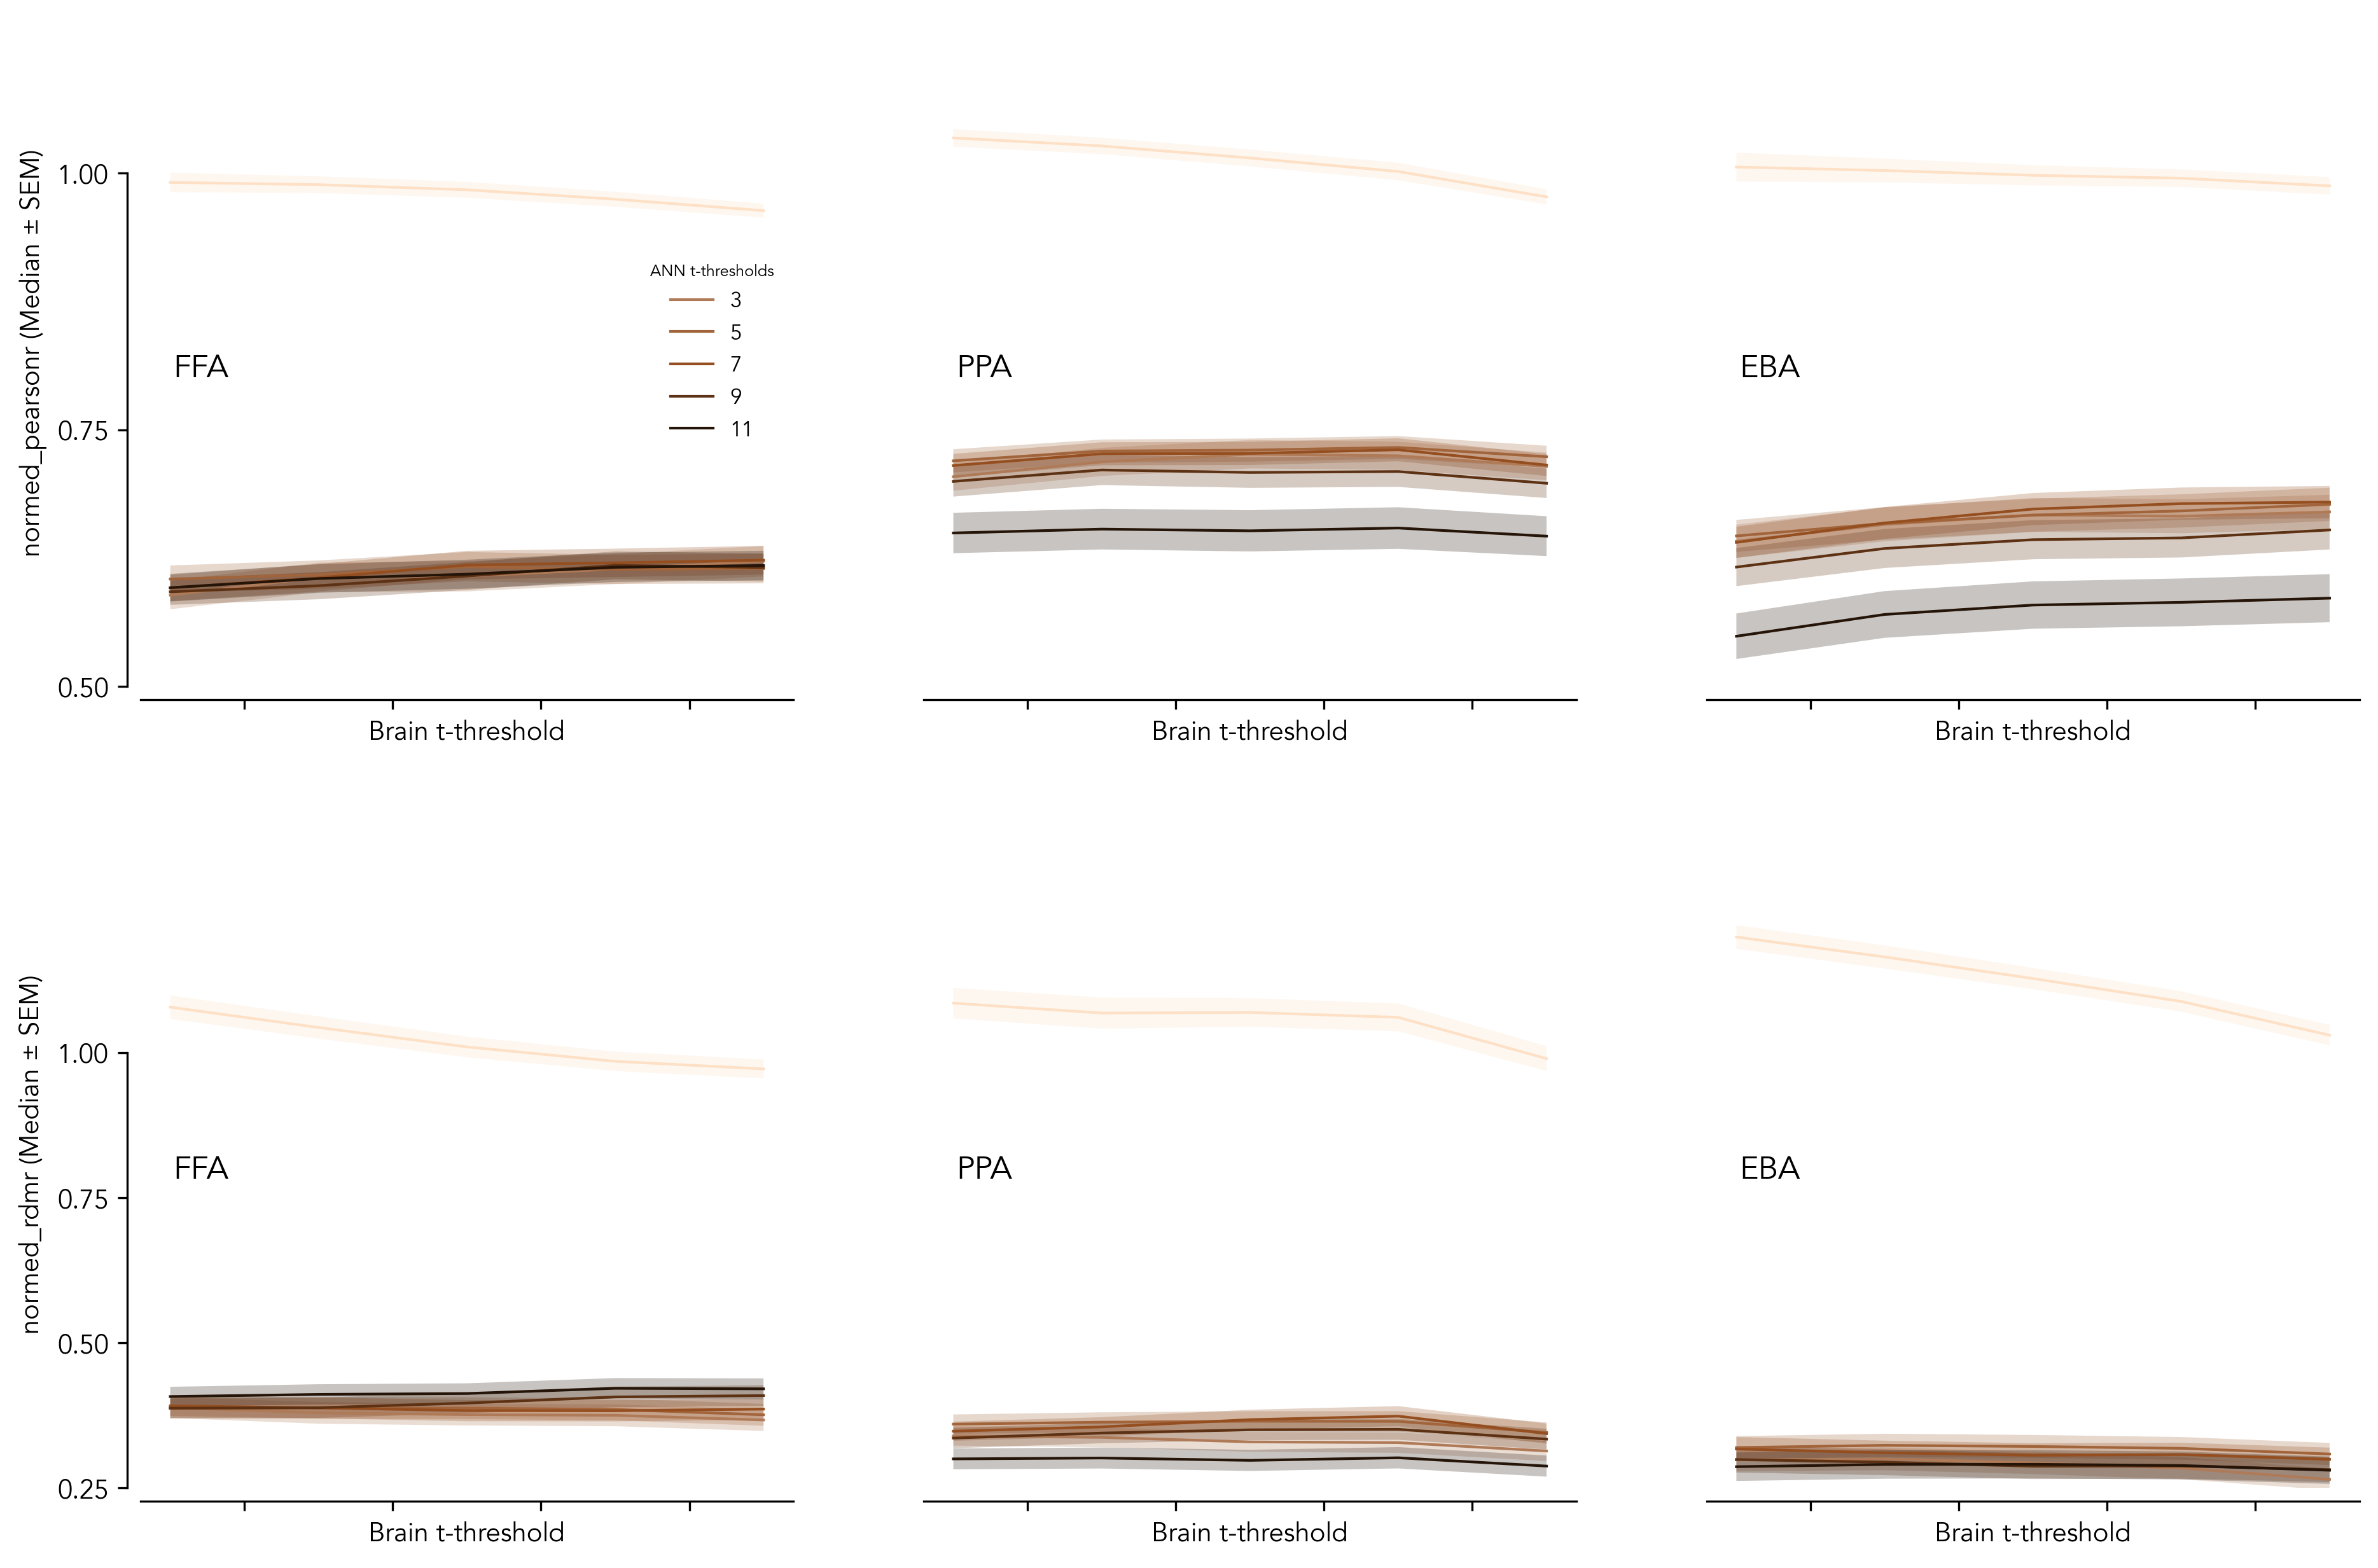

In [ ]:
savefig = False

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

metrics = ['normed_pearsonr', 'normed_rdmr'] 
ceiling_color = '#fde0c5'
model_t_color_base = '#944e1f'
model_t_colors = get_shades(model_t_color_base, n=5)
metric_ylims = {
    'normed_pearsonr': (0.5, 1.15),
    'normed_rdmr': (0.25, 1.4)
}

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    for fidx, froi in enumerate(frois):
        froi_median_gaps = {}
        froi_max_gaps = {}
        # Get ceilings and plot median line plot with shaded area as SEM
        ceiling_medians, ceiling_sems = [], []
        for ftidx, fmri_tthreshold in enumerate(tthresholds):
            sbjsbj_corrs = np.array(subjectsubject_correlations_csv[
                    (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                    (subjectsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold)
                ][metric])
            sbjsbj_median = np.median(sbjsbj_corrs)
            sbjsbj_sem = np.nanstd(sbjsbj_corrs) / np.sqrt(len(sbjsbj_corrs))
            ceiling_medians.append(sbjsbj_median)
            ceiling_sems.append(sbjsbj_sem)
        # line plot with shaded area for ceiling
        axs[midx, fidx].plot(tthresholds, ceiling_medians, color=ceiling_color, linewidth=1, alpha=1)
        axs[midx, fidx].fill_between(
            tthresholds,
            np.array(ceiling_medians) - np.array(ceiling_sems),
            np.array(ceiling_medians) + np.array(ceiling_sems),
            facecolor=ceiling_color, alpha=0.25,
            edgecolor="none", linewidth=0
        )
        for mtidx, model_tthreshold in enumerate(tthresholds):
            t_mdlsbj_medians, t_mdlsbj_sems = [], []
            for ftidx, fmri_tthreshold in enumerate(tthresholds):
                # For model_tthreshold calculate median and max model-subject correlation across all models
                mdlsbj_csv = modelsubject_correlations_csv[
                        (modelsubject_correlations_csv['fmri_froi'] == froi) &
                        (modelsubject_correlations_csv['model_froi'] == froi) &
                        (modelsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold) &
                        (modelsubject_correlations_csv['model_tthreshold'] == model_tthreshold) &
                        (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                    ]
                # Aggregate according to model name and take median across subjects
                mdlsbj_agg = mdlsbj_csv.groupby('model_name').agg({metric: 'median'})
                # get median and max of the aggregated values
                mdlsbj_median = mdlsbj_agg[metric].median()
                mdlsbj_sem = mdlsbj_agg[metric].sem() #TODO: Fix for NaNs
                t_mdlsbj_medians.append(mdlsbj_median)
                t_mdlsbj_sems.append(mdlsbj_sem)
            # line plot with shaded area for this model tthreshold
            model_t_color = model_t_colors[mtidx]
            axs[midx, fidx].plot(
                tthresholds, t_mdlsbj_medians, color=model_t_color, linewidth=1, alpha=1,
                label=f'{model_tthreshold}' if fidx == 0 else None
            )
            axs[midx, fidx].fill_between(
                tthresholds,
                np.array(t_mdlsbj_medians) - np.array(t_mdlsbj_sems),
                np.array(t_mdlsbj_medians) + np.array(t_mdlsbj_sems),
                facecolor=model_t_color, alpha=0.25,
                edgecolor="none", linewidth=0,
            )
        # Median line plot
        # median_heatmap_ax = sns.heatmap(
        #     froi_median_gaps_df, annot=True, fmt='.3f', cmap=cmap, center=0, ax=axs[midx, fidx],
        #     vmin=median_vmin, vmax=median_vmax
        # )
        axs[midx, fidx].set_xlabel('Brain t-threshold')
        axs[midx, fidx].set_ylabel(f'{metric} (Median ± SEM)')
        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        if metric == 'normed_pearsonr':
            axs[midx, fidx].set_yticks([0.5, 0.75, 1])
            axs[midx, fidx].spines['left'].set_bounds(0.5, 1)
        else:
            axs[midx, fidx].set_yticks([0.25, 0.5, 0.75, 1])
            axs[midx, fidx].spines['left'].set_bounds(0.25, 1)
        # axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        # axs[midx, fidx].spines['left'].set_bounds(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        # axs[midx, fidx].set_ylim(-0.25, 1.15)
        axs[midx, fidx].set_ylim(metric_ylims[metric])
        # axs[midx, fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[-1])
        # axs[midx, fidx].set_xlim(bar_positions[0]-0.25, bar_positions[-1]+0.25)
        axs[midx, fidx].tick_params(axis='x', labelbottom=False)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

        # Write froi name in bottom left corner
        axs[midx, fidx].text(0.05, 0.5, froi, transform=axs[midx, fidx].transAxes, fontsize=12, verticalalignment='top')

        # Plot legend
        if fidx == 0 and midx == 0:
            axs[midx, fidx].legend(
                loc='center right', fontsize=8,
                title='ANN t-thresholds', title_fontsize='6', frameon=False
            )
if savefig:
    raise NotImplementedError("Change the file name")
    fig.savefig(f'{plot_dir}/fig4_tthreshold_modelbrainsimilarity_lineplot.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close(fig)

### Line plots (x-axis = ANN-tthreshold)

#### y-axis = correlations

In [ ]:
savefig = False

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

metrics = ['normed_pearsonr', 'normed_rdmr'] 
fmri_t_color_base = '#fde0c5'
model_t_color_base = '#944e1f'
modelsubject_t_colors = get_shades(model_t_color_base, n=5)
metric_ylims = {
    'normed_pearsonr': (0.5, 0.75),
    'normed_rdmr': (0.25, 0.5)
}

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    for fidx, froi in enumerate(frois):
        froi_median_gaps = {}
        froi_max_gaps = {}
        # Get ceilings and plot median line plot with shaded area as SEM
        # ceiling_medians, ceiling_sems = [], []
        # for ftidx, fmri_tthreshold in enumerate(tthresholds):
        #     sbjsbj_corrs = np.array(subjectsubject_correlations_csv[
        #             (subjectsubject_correlations_csv['fmri_froi'] == froi) &
        #             (subjectsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold)
        #         ][metric])
        #     sbjsbj_median = np.median(sbjsbj_corrs)
        #     sbjsbj_sem = np.nanstd(sbjsbj_corrs) / np.sqrt(len(sbjsbj_corrs))
        #     ceiling_medians.append(sbjsbj_median)
        #     ceiling_sems.append(sbjsbj_sem)
        # line plot with shaded area for ceiling
        # axs[midx, fidx].plot(tthresholds, ceiling_medians, color=ceiling_color, linewidth=1, alpha=1)
        # axs[midx, fidx].fill_between(
        #     tthresholds,
        #     np.array(ceiling_medians) - np.array(ceiling_sems),
        #     np.array(ceiling_medians) + np.array(ceiling_sems),
        #     facecolor=ceiling_color, alpha=0.25,
        #     edgecolor="none", linewidth=0
        # )
        for ftidx, fmri_tthreshold in enumerate(tthresholds):
            t_mdlsbj_medians, t_mdlsbj_sems = [], []
            for mtidx, model_tthreshold in enumerate(tthresholds):
                # For model_tthreshold calculate median and max model-subject correlation across all models
                mdlsbj_csv = modelsubject_correlations_csv[
                        (modelsubject_correlations_csv['fmri_froi'] == froi) &
                        (modelsubject_correlations_csv['model_froi'] == froi) &
                        (modelsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold) &
                        (modelsubject_correlations_csv['model_tthreshold'] == model_tthreshold) &
                        (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                    ]
                # Aggregate according to model name and take median across subjects
                mdlsbj_agg = mdlsbj_csv.groupby('model_name').agg({metric: 'median'})
                # get median and max of the aggregated values
                mdlsbj_median = mdlsbj_agg[metric].median()
                mdlsbj_sem = mdlsbj_agg[metric].sem() #TODO: Fix for NaNs
                t_mdlsbj_medians.append(mdlsbj_median)
                t_mdlsbj_sems.append(mdlsbj_sem)
            # line plot with shaded area for this model tthreshold
            fmri_t_color = modelsubject_t_colors[ftidx]
            axs[midx, fidx].plot(
                tthresholds, t_mdlsbj_medians, '.-', color=fmri_t_color, linewidth=1, alpha=1,
                label=f'{fmri_tthreshold}' if fidx == 0 else None
            )
            axs[midx, fidx].errorbar(
                tthresholds, t_mdlsbj_medians, yerr=t_mdlsbj_sems,
                fmt='none', ecolor=fmri_t_color, elinewidth=1, alpha=0.75, capsize=0
            )
            # axs[midx, fidx].fill_between(
            #     tthresholds,
            #     np.array(t_mdlsbj_medians) - np.array(t_mdlsbj_sems),
            #     np.array(t_mdlsbj_medians) + np.array(t_mdlsbj_sems),
            #     facecolor=fmri_t_color, alpha=0.25,
            #     edgecolor="none", linewidth=0,
            # )
        # Median line plot
        # median_heatmap_ax = sns.heatmap(
        #     froi_median_gaps_df, annot=True, fmt='.3f', cmap=cmap, center=0, ax=axs[midx, fidx],
        #     vmin=median_vmin, vmax=median_vmax
        # )
        axs[midx, fidx].set_xlabel('ANN t-threshold')
        axs[midx, fidx].set_ylabel(f'{metric} (Median ± SEM)')
        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        if metric == 'normed_pearsonr':
            axs[midx, fidx].set_yticks([0.5, 0.75])
            axs[midx, fidx].spines['left'].set_bounds(0.5, 0.75)
        elif metric == 'normed_rdmr':
            axs[midx, fidx].set_yticks([0.25, 0.5])
            axs[midx, fidx].spines['left'].set_bounds(0.25, 0.5)
        axs[midx, fidx].set_xticks(tthresholds)
        # axs[midx, fidx].spines['left'].set_bounds(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        # axs[midx, fidx].set_ylim(-0.25, 1.15)
        axs[midx, fidx].set_ylim(metric_ylims[metric])
        # axs[midx, fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[-1])
        # axs[midx, fidx].set_xlim(bar_positions[0]-0.25, bar_positions[-1]+0.25)
        # axs[midx, fidx].tick_params(axis='x', labelbottom=False)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

        # Write froi name in bottom left corner
        axs[midx, fidx].text(0.95, 0.85, froi, transform=axs[midx, fidx].transAxes, fontsize=12, verticalalignment='top')

        # Plot legend
        if fidx == 0 and midx == 0:
            axs[midx, fidx].legend(
                loc='upper left', fontsize=8,
                title='Brain t-thresholds', title_fontsize='6', frameon=False
            )
if savefig:
    raise NotImplementedError("Should be plotting y-axis as gaps")
    fig.savefig(f'{plot_dir}/fig4_tthreshold_modelbrainsimilarity_lineplot.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close(fig)

#### y-axis = gaps

In [4]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

metrics = ['normed_pearsonr', 'normed_rdmr'] 
fmri_t_color_base = '#fde0c5'
model_t_color_base = '#944e1f'
modelsubject_t_colors = get_shades(model_t_color_base, n=5)
metric_ylims = {
    'normed_pearsonr': (0.25, 0.5),
    'normed_rdmr': (0.5, 1)
}

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    for fidx, froi in enumerate(frois):
        for ftidx, fmri_tthreshold in enumerate(tthresholds):
            # Get the subject-subject ceiling for the gap
            sbjsbj_corrs = np.array(subjectsubject_correlations_csv[
                    (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                    (subjectsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold)
                ][metric])
            ceiling_median = np.median(sbjsbj_corrs)
            # Get model-subject correlations
            t_mdlsbj_medians, t_mdlsbj_sems = [], []
            for mtidx, model_tthreshold in enumerate(tthresholds):
                # For model_tthreshold calculate median and max model-subject correlation across all models
                mdlsbj_csv = modelsubject_correlations_csv[
                        (modelsubject_correlations_csv['fmri_froi'] == froi) &
                        (modelsubject_correlations_csv['model_froi'] == froi) &
                        (modelsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold) &
                        (modelsubject_correlations_csv['model_tthreshold'] == model_tthreshold) &
                        (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                    ]
                # Aggregate according to model name and take median across subjects
                mdlsbj_agg = mdlsbj_csv.groupby('model_name').agg({metric: 'median'})
                # get median and max of the aggregated values
                mdlsbj_median = mdlsbj_agg[metric].median()
                mdlsbj_sem = mdlsbj_agg[metric].sem() #TODO: Fix for NaNs
                t_mdlsbj_medians.append(ceiling_median - mdlsbj_median)
                t_mdlsbj_sems.append(mdlsbj_sem)
            # line plot with shaded area for this model tthreshold
            fmri_t_color = modelsubject_t_colors[ftidx]
            axs[midx, fidx].plot(
                tthresholds, t_mdlsbj_medians, '.-', color=fmri_t_color, linewidth=1, alpha=1,
                label=f'{fmri_tthreshold}' if fidx == 0 else None
            )
            axs[midx, fidx].errorbar(
                tthresholds, t_mdlsbj_medians, yerr=t_mdlsbj_sems,
                fmt='none', ecolor=fmri_t_color, elinewidth=1, alpha=0.75, capsize=0
            )
        axs[midx, fidx].set_xlabel('ANN t-threshold')
        axs[midx, fidx].set_ylabel(rf'$\Delta$ {metric}')
        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        if metric == 'normed_pearsonr':
            axs[midx, fidx].set_yticks([0.25, 0.5])
            axs[midx, fidx].spines['left'].set_bounds(0.25, 0.5)
        elif metric == 'normed_rdmr':
            axs[midx, fidx].set_yticks([0.5, 0.75, 1])
            axs[midx, fidx].spines['left'].set_bounds(0.5, 1)
        axs[midx, fidx].set_xticks(tthresholds)
        # axs[midx, fidx].spines['left'].set_bounds(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        # axs[midx, fidx].set_ylim(-0.25, 1.15)
        axs[midx, fidx].set_ylim(metric_ylims[metric])
        # axs[midx, fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[-1])
        # axs[midx, fidx].set_xlim(bar_positions[0]-0.25, bar_positions[-1]+0.25)
        # axs[midx, fidx].tick_params(axis='x', labelbottom=False)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

        # Write froi name in bottom left corner
        axs[midx, fidx].text(0.5, 0.85, froi, transform=axs[midx, fidx].transAxes, fontsize=12, verticalalignment='top')

        # Plot legend
        if fidx == 0 and midx == 0:
            axs[midx, fidx].legend(
                loc='upper left', fontsize=8,
                title='Brain t-thresholds', title_fontsize='6', frameon=False
            )
if savefig:
    fig.savefig(f'{plot_dir}/fig4_tthreshold_modelbrainsimilarity_lineplot.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close(fig)

### Univariate: Median & Max gaps

#### Stats

In [22]:
metric = 'normed_pearsonr'

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

for fidx, froi in enumerate(frois):
    median_gap_stats = []
    for fmri_tthreshold in tthresholds:
        # For fmri_tthreshold calculate median subject-subject correlation across all subjects
        sbjsbj_corrs = np.array(subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold)
            ][metric])
        sbjsbj_median = np.median(sbjsbj_corrs)
        for model_tthreshold in tthresholds:
            # For model_tthreshold calculate median and max model-subject correlation across all models
            mdlsbj_csv = modelsubject_correlations_csv[
                    (modelsubject_correlations_csv['fmri_froi'] == froi) &
                    (modelsubject_correlations_csv['model_froi'] == froi) &
                    (modelsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold) &
                    (modelsubject_correlations_csv['model_tthreshold'] == model_tthreshold) &
                    (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                ]
            # Aggregate according to model name and take median across subjects
            mdlsbj_agg = mdlsbj_csv.groupby('model_name').agg({metric: 'median'})
            # get median and max of the aggregated values
            mdlsbj_median = mdlsbj_agg[metric].median()
            mdlsbj_max = mdlsbj_agg[metric].max()
            # Conduct t-tests for median
            sbjsbj_normativity_pval = scipy.stats.shapiro(sbjsbj_corrs, nan_policy='omit')[1]
            mdlsbj_normativity_pval = scipy.stats.shapiro(mdlsbj_agg[metric], nan_policy='omit')[1]
            # Conduct t-tests
            median_tval, median_pval = scipy.stats.ttest_ind(
                sbjsbj_corrs, mdlsbj_agg[metric], equal_var=False, alternative='greater',
                nan_policy='omit'
            )
            median_mw_tval, median_mw_pval = scipy.stats.mannwhitneyu(
                sbjsbj_corrs, mdlsbj_agg[metric], alternative='greater', use_continuity=True,
                nan_policy='omit'
            )
            median_gap_stats.append({
                'fmri_tthreshold': fmri_tthreshold,
                'model_tthreshold': model_tthreshold,
                'sbjsbj_norm_pval': sbjsbj_normativity_pval,
                'mdlsbj_norm_pval': mdlsbj_normativity_pval,
                'median_gap_tval': median_tval,
                'median_gap_pval': median_pval,
                'median_gap_mw_tval': median_mw_tval,
                'median_gap_mw_pval': median_mw_pval,
            })
            # Conduct t-tests for max
            # max_tval, max_pval = scipy.stats.ttest_ind(sbjsbj_corrs, mdlsbj_agg[metric], equal_var=False)
    print(f'FROI: {froi}')
    median_gap_stats = pd.DataFrame(median_gap_stats)
    display(median_gap_stats)

FROI: FFA


,fmri_tthreshold,model_tthreshold,sbjsbj_norm_pval,mdlsbj_norm_pval,median_gap_tval,median_gap_pval,median_gap_mw_tval,median_gap_mw_pval
0,3,3,0.342879,0.696390,23.853258,5.677480e-32,980.0,6.403398e-12
1,3,5,0.342879,0.823074,23.866891,2.816449e-32,980.0,6.403398e-12
2,3,7,0.342879,0.969519,24.114583,1.144491e-32,980.0,6.403398e-12
3,3,9,0.342879,0.805052,24.462876,4.461202e-33,980.0,6.403398e-12
4,3,11,0.342879,0.867053,24.045666,2.428500e-32,980.0,6.403398e-12
5,5,3,0.458968,0.760857,23.435301,6.369351e-30,980.0,6.403398e-12
6,5,5,0.458968,0.810968,23.400534,2.964572e-30,980.0,6.403398e-12
7,5,7,0.458968,0.866758,23.743319,7.426227e-31,980.0,6.403398e-12
8,5,9,0.458968,0.856183,24.108926,2.449794e-31,980.0,6.403398e-12
9,5,11,0.458968,0.945660,23.685353,1.728443e-30,980.0,6.403398e-12


FROI: PPA


,fmri_tthreshold,model_tthreshold,sbjsbj_norm_pval,mdlsbj_norm_pval,median_gap_tval,median_gap_pval,median_gap_mw_tval,median_gap_mw_pval
0,3,3,0.232566,0.003874,21.497017,5.913447e-29,980.0,6.403398e-12
1,3,5,0.232566,0.048376,23.086828,8.583819e-32,980.0,6.403398e-12
2,3,7,0.232566,0.050869,22.977483,1.154641e-31,980.0,6.403398e-12
3,3,9,0.232566,0.002611,21.081339,6.713816e-28,980.0,6.403398e-12
4,3,11,0.232566,0.014509,19.355224,8.819358e-24,952.0,8.723673e-12
5,5,3,0.231876,0.003261,20.708084,1.244088e-27,980.0,6.403398e-12
6,5,5,0.231876,0.028732,22.501119,6.606658e-31,980.0,6.403398e-12
7,5,7,0.231876,0.030116,22.481494,6.813987e-31,980.0,6.403398e-12
8,5,9,0.231876,0.001950,20.490347,7.026553e-27,980.0,6.403398e-12
9,5,11,0.231876,0.015667,18.659546,9.847362e-23,952.0,8.723673e-12


FROI: EBA


,fmri_tthreshold,model_tthreshold,sbjsbj_norm_pval,mdlsbj_norm_pval,median_gap_tval,median_gap_pval,median_gap_mw_tval,median_gap_mw_pval
0,3,3,0.093564,0.057583,18.876064,1.856793e-27,980.0,6.403398e-12
1,3,5,0.093564,0.044983,18.732043,2.853502e-27,980.0,6.403398e-12
2,3,7,0.093564,0.029630,19.214303,8.174611e-28,980.0,6.403398e-12
3,3,9,0.093564,0.005436,18.211163,2.159371e-26,980.0,6.403398e-12
4,3,11,0.093564,0.108554,18.329938,1.202490e-25,980.0,6.403398e-12
5,5,3,0.374520,0.030869,19.028067,4.933625e-27,980.0,6.403398e-12
6,5,5,0.374520,0.022582,18.847738,5.570134e-27,980.0,6.403398e-12
7,5,7,0.374520,0.013613,19.292646,1.340584e-27,980.0,6.403398e-12
8,5,9,0.374520,0.004586,18.036311,4.819400e-25,980.0,6.403398e-12
9,5,11,0.374520,0.108927,18.057226,6.848134e-24,980.0,6.403398e-12


#### Plot

In [84]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

metric = 'normed_pearsonr'
cmap = "Blues"
median_vmin, median_vmax = 0.25, 0.5
max_vmin, max_vmax = 0.1, 0.3

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

median_fig, median_axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)
max_fig, max_axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)

for fidx, froi in enumerate(frois):
    froi_median_gaps = {}
    froi_max_gaps = {}
    for fmri_tthreshold in tthresholds:
        # For fmri_tthreshold calculate median subject-subject correlation across all subjects
        sbjsbj_corrs = np.array(subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold)
            ][metric])
        sbjsbj_median = np.median(sbjsbj_corrs)
        froi_median_gaps[fmri_tthreshold] = {}
        froi_max_gaps[fmri_tthreshold] = {}
        for model_tthreshold in tthresholds:
            # For model_tthreshold calculate median and max model-subject correlation across all models
            mdlsbj_csv = modelsubject_correlations_csv[
                    (modelsubject_correlations_csv['fmri_froi'] == froi) &
                    (modelsubject_correlations_csv['model_froi'] == froi) &
                    (modelsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold) &
                    (modelsubject_correlations_csv['model_tthreshold'] == model_tthreshold) &
                    (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                ]
            # Aggregate according to model name and take median across subjects
            mdlsbj_agg = mdlsbj_csv.groupby('model_name').agg({metric: 'median'})
            # get median and max of the aggregated values
            mdlsbj_median = mdlsbj_agg[metric].median()
            mdlsbj_max = mdlsbj_agg[metric].max()
            # Estimate the gap
            gap_median = sbjsbj_median - mdlsbj_median
            gap_max = sbjsbj_median - mdlsbj_max
            froi_median_gaps[fmri_tthreshold][model_tthreshold] = gap_median
            froi_max_gaps[fmri_tthreshold][model_tthreshold] = gap_max
    froi_median_gaps_df = pd.DataFrame(froi_median_gaps).T
    froi_max_gaps_df = pd.DataFrame(froi_max_gaps).T
    # Median heatmap
    median_heatmap_ax = sns.heatmap(
        froi_median_gaps_df, annot=True, fmt='.3f', cmap=cmap, center=0, ax=median_axs[fidx],
        vmin=median_vmin, vmax=median_vmax
    )
    median_axs[fidx].set_title(f'Median Gap (Subject-Subject - Model-Subject)')
    median_axs[fidx].set_xlabel('Model t-threshold')
    median_axs[fidx].set_ylabel('fMRI t-threshold')
    if froi != 'FFA':
        median_axs[fidx].set_ylabel('')
        median_axs[fidx].set_yticks([])
        median_axs[fidx].set_xlabel('')
        median_axs[fidx].set_xticks([])
    median_axs[fidx].set_title(froi)
    # Max heatmap
    max_heatmap_ax = sns.heatmap(
        froi_max_gaps_df, annot=True, fmt='.3f', cmap=cmap, center=0, ax=max_axs[fidx],
        vmin=max_vmin, vmax=max_vmax
    )
    max_axs[fidx].set_title(f'Max Gap (Subject-Subject - Model-Subject)')
    max_axs[fidx].set_xlabel('Model t-threshold')
    max_axs[fidx].set_ylabel('fMRI t-threshold')
    if froi != 'FFA':
        max_axs[fidx].set_ylabel('')
        max_axs[fidx].set_yticks([])
        max_axs[fidx].set_xlabel('')
        max_axs[fidx].set_xticks([])
    ## Colorbar ticks
    max_cbar = max_heatmap_ax.collections[0].colorbar
    max_cbar.set_ticks([0.1, 0.15, 0.2, 0.25, 0.3])
    max_cbar.set_ticklabels([0.1, 0.15, 0.2, 0.25, 0.3])
    if fidx != len(frois) - 1:
        # Remove colorbars for all but the last subplot
        if median_heatmap_ax.collections and median_heatmap_ax.collections[0].colorbar:
            median_heatmap_ax.collections[0].colorbar.remove()
        if max_heatmap_ax.collections and max_heatmap_ax.collections[0].colorbar:
            max_heatmap_ax.collections[0].colorbar.remove()
    max_axs[fidx].set_title(froi)
if savefig:
    median_fig.savefig(f'{plot_dir}/fig4a_heatmap_median_gap_univariate_allfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
    max_fig.savefig(f'{plot_dir}/sup_fig4a_heatmap_max_gap_univariate_allfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close(median_fig)
plt.close(max_fig)

### Multivariate: Median & Max gaps

In [85]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

metric = 'normed_rdmr'
cmap = "Blues"
median_vmin, median_vmax = 0.5, 1
max_vmin, max_vmax = 0.3, 0.7

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

median_fig, median_axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)
max_fig, max_axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)

for fidx, froi in enumerate(frois):
    froi_median_gaps = {}
    froi_max_gaps = {}
    for fmri_tthreshold in tthresholds:
        # For fmri_tthreshold calculate median subject-subject correlation across all subjects
        sbjsbj_corrs = np.array(subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold)
            ][metric])
        sbjsbj_median = np.median(sbjsbj_corrs)
        froi_median_gaps[fmri_tthreshold] = {}
        froi_max_gaps[fmri_tthreshold] = {}
        for model_tthreshold in tthresholds:
            # For model_tthreshold calculate median and max model-subject correlation across all models
            mdlsbj_csv = modelsubject_correlations_csv[
                    (modelsubject_correlations_csv['fmri_froi'] == froi) &
                    (modelsubject_correlations_csv['model_froi'] == froi) &
                    (modelsubject_correlations_csv['fmri_tthreshold'] == fmri_tthreshold) &
                    (modelsubject_correlations_csv['model_tthreshold'] == model_tthreshold) &
                    (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                ]
            # Aggregate according to model name and take median across subjects
            mdlsbj_agg = mdlsbj_csv.groupby('model_name').agg({metric: 'median'})
            # get median and max of the aggregated values
            mdlsbj_median = mdlsbj_agg[metric].median()
            mdlsbj_max = mdlsbj_agg[metric].max()
            # Estimate the gap
            gap_median = sbjsbj_median - mdlsbj_median
            gap_max = sbjsbj_median - mdlsbj_max
            froi_median_gaps[fmri_tthreshold][model_tthreshold] = gap_median
            froi_max_gaps[fmri_tthreshold][model_tthreshold] = gap_max
    froi_median_gaps_df = pd.DataFrame(froi_median_gaps).T
    froi_max_gaps_df = pd.DataFrame(froi_max_gaps).T
    # Median heatmap
    median_heatmap_ax = sns.heatmap(
        froi_median_gaps_df, annot=True, fmt='.3f', cmap=cmap, center=0, ax=median_axs[fidx],
        vmin=median_vmin, vmax=median_vmax
    )
    median_axs[fidx].set_title(f'Median Gap (Subject-Subject - Model-Subject)')
    median_axs[fidx].set_xlabel('Model t-threshold')
    median_axs[fidx].set_ylabel('fMRI t-threshold')
    if froi != 'FFA':
        median_axs[fidx].set_ylabel('')
        median_axs[fidx].set_yticks([])
        median_axs[fidx].set_xlabel('')
        median_axs[fidx].set_xticks([])
    median_axs[fidx].set_title(froi)
    # Max heatmap
    max_heatmap_ax = sns.heatmap(
        froi_max_gaps_df, annot=True, fmt='.3f', cmap=cmap, center=0, ax=max_axs[fidx],
        vmin=max_vmin, vmax=max_vmax
    )
    max_axs[fidx].set_title(f'Max Gap (Subject-Subject - Model-Subject)')
    max_axs[fidx].set_xlabel('Model t-threshold')
    max_axs[fidx].set_ylabel('fMRI t-threshold')
    if froi != 'FFA':
        max_axs[fidx].set_ylabel('')
        max_axs[fidx].set_yticks([])
        max_axs[fidx].set_xlabel('')
        max_axs[fidx].set_xticks([])
    ## Colorbar ticks
    max_cbar = max_heatmap_ax.collections[0].colorbar
    max_cbar.set_ticks([0.3, 0.4, 0.5, 0.6, 0.7])
    max_cbar.set_ticklabels([0.3, 0.4, 0.5, 0.6, 0.7])
    if fidx != len(frois) - 1:
        # Remove colorbars for all but the last subplot
        if median_heatmap_ax.collections and median_heatmap_ax.collections[0].colorbar:
            median_heatmap_ax.collections[0].colorbar.remove()
        if max_heatmap_ax.collections and max_heatmap_ax.collections[0].colorbar:
            max_heatmap_ax.collections[0].colorbar.remove()
    max_axs[fidx].set_title(froi)
if savefig:
    median_fig.savefig(f'{plot_dir}/fig4c_heatmap_median_gap_multivariate_allfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
    max_fig.savefig(f'{plot_dir}/sup_fig4c_heatmap_max_gap_multivariate_allfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close(median_fig)
plt.close(max_fig)

## Localizer

### Exploration: Comparing localizer gaps

In [25]:
tthreshold = 7
frois = ['FFA', 'PPA', 'EBA']
model_localizers = ['grillspector', 'kanwisher']

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/localizer_effect_correlations_nsd515.csv'

In [71]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

# hh_color = 'blue'
# mh_color = 'red'
# colors = [hh_color, mh_color]

metrics = ['normed_pearsonr', 'normed_rdmr']

# fig, ax = plt.figure(figsize=(5, 5), dpi=300)
# fig, axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)
fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)
x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3]

loc_gap_df = []
for midx, metric in enumerate(metrics):
    for fidx, froi in enumerate(frois):
        hh_medians = []
        for subject in subjects:
            subjectsubject_froi = subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['subject1'] == subject) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
            ]
            hh_medians += list(subjectsubject_froi[metric])
        hh_medians = np.array(hh_medians).flatten()
        hh_median = np.median(hh_medians)

        median_gaps = [] # List of median gaps for each model localizer (grillspector, kanwisher)
        for model in models:
            model_gaps = [0, 0] # [grillspector, kanwisher]
            for lidx, model_localizer in enumerate(model_localizers):
                modelsubject_froi = modelsubject_correlations_csv[
                    (modelsubject_correlations_csv['fmri_froi'] == froi) &
                    (modelsubject_correlations_csv['model_name'] == model) &
                    (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                    (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                    (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                ]
                model_loc_mh_median = modelsubject_froi[metric].median()
                model_loc_median_gap = hh_median - model_loc_mh_median
                model_gaps[lidx] = model_loc_median_gap.item()
            median_gaps.append(model_gaps)  # Append the mean gap for the model across localizers
        median_gaps = np.array(median_gaps)

        # Plot
        gs_pts = median_gaps[:, 0]  # Grillspector gaps
        kw_pts = median_gaps[:, 1]  # Kanwisher gaps

        x_gs = (np.ones(len(gs_pts)) * x[0]) - x_offset
        x_kw = (np.ones(len(kw_pts)) * x[1]) - x_offset

        axs[midx, fidx].scatter(
            x_gs, gs_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_kw, kw_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        # connect points with a line
        for i in range(len(gs_pts)):
            axs[midx, fidx].plot([x_gs[i], x_kw[i]], [gs_pts[i], kw_pts[i]], color='red', alpha=0.2, linewidth=0.5, zorder=1)

        # Bar plot with median and SEM
        bar_width = 0.2 #0.4
        medians = [np.median(gs_pts), np.median(kw_pts)]
        sems = [gs_pts.std() / np.sqrt(len(gs_pts)), kw_pts.std() / np.sqrt(len(kw_pts))]

        axs[midx, fidx].bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
        
        # Stats
        # Conduct normativity test (Shapiro-Wilk test)
        gs_norm_pval = scipy.stats.shapiro(gs_pts, nan_policy='omit')[1]
        kw_norm_pval = scipy.stats.shapiro(kw_pts, nan_policy='omit')[1]
        # Conduct Welch's t-test for median
        kw_gs_t_value, kw_gs_p_value = scipy.stats.ttest_ind(
            kw_pts, gs_pts, equal_var=False, nan_policy='omit', alternative='less'
        )
        # Conduct Mann-Whitney U test for median
        kw_gs_mw_t_value, kw_gs_mw_p_value = scipy.stats.mannwhitneyu(
            kw_pts, gs_pts, alternative='less', use_continuity=True, nan_policy='omit'
        )
        # Estimate spearman rank correlation between the two localizers
        spearman_rho, spearman_pval = scipy.stats.spearmanr(-gs_pts, -kw_pts, nan_policy='omit')

        loc_gap_df.append({
            'froi': froi,
            'metric': metric,
            'gs_norm_pval': gs_norm_pval,
            'kw_norm_pval': kw_norm_pval,
            'kw<gs_mw_u_value': kw_gs_mw_t_value,
            'kw<gs_mw_p_value': kw_gs_mw_p_value,
            'kw<gs_t_value': kw_gs_t_value,
            'kw<gs_p_value': kw_gs_p_value,
            'model_ranks_spearman_rho': spearman_rho,
            'model_ranks_spearman_pval': spearman_pval,
        })

        # Label fROI
        axs[midx, fidx].text(0.9, 0.9,
                 froi,
                 horizontalalignment='right', verticalalignment='bottom',
                 transform=axs[midx, fidx].transAxes)
        # Mention the spearman rank correlation and p-value
        # {chr(10)} is new line
        axs[midx, fidx].text(0.3, 0.95,
                 rf'Model ranks{chr(10)}Spearman $\rho$={spearman_rho:.2f}{chr(10)}p={spearman_pval:.2e}',
                    horizontalalignment='right', verticalalignment='bottom',
                    transform=axs[midx, fidx].transAxes, fontsize=8)

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        plt.ylim(0, 1.1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[1])
        axs[midx, fidx].set_xticks(x, ['Stigliani et al., 2015', 'Julian et al., 2012'])
        axs[midx, fidx].set_xlim(x[0]-0.25, x[1]+0.25)
        # plt.tick_params(axis='x', labelbottom=False)
        # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx, fidx].set_ylabel(rf'$\Delta$ {metric.split("_")[-1]} (brain-to-brain - model-to-brain)', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

loc_gap_df = pd.DataFrame(loc_gap_df)
# sort df according to froi
loc_gap_df = loc_gap_df.sort_values(by=['froi', 'metric'])
display(loc_gap_df)

if savefig:
    plt.savefig(f'{plot_dir}/fig4x1_localizer_gaps.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()

,froi,metric,gs_norm_pval,kw_norm_pval,kw<gs_mw_u_value,kw<gs_mw_p_value,kw<gs_t_value,kw<gs_p_value,model_ranks_spearman_rho,model_ranks_spearman_pval
2,EBA,normed_pearsonr,0.007751,0.080730,944.0,0.999952,4.209975,0.999955,0.642297,3.187893e-05
5,EBA,normed_rdmr,0.065105,0.010673,764.0,0.962902,1.618525,0.944825,0.842577,2.187725e-10
0,FFA,normed_pearsonr,0.825290,0.055484,820.0,0.992721,2.242719,0.985833,0.589636,1.934766e-04
3,FFA,normed_rdmr,0.140225,0.402907,701.0,0.852081,0.940550,0.824865,0.891877,6.521502e-13
1,PPA,normed_pearsonr,0.031438,0.055440,1225.0,1.000000,19.192436,1.000000,-0.200560,2.479990e-01
4,PPA,normed_rdmr,0.992329,0.328930,1137.0,1.000000,8.787866,1.000000,0.188796,2.774037e-01


### Effect of localizer

In [57]:
tthreshold = 7
frois = ['FFA', 'PPA', 'EBA']
model_localizers = ['grillspector', 'kanwisher']

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/localizer_effect_correlations_nsd515.csv'

#### Boxplots

In [62]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = '#fde0c5'
mh_color = '#944e1f'
colors = [hh_color, mh_color, mh_color]

metrics = ['normed_pearsonr', 'normed_rdmr']
metric_ylims = {
    'normed_pearsonr': (-0.25, 1.15),
    'normed_rdmr': (-0.1, 1.4)
}

# fig, ax = plt.figure(figsize=(5, 5), dpi=300)
# fig, axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)
fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

stats_df = []

for midx, metric in enumerate(metrics):
    for fidx, froi in enumerate(frois):
        hh_medians = []
        for subject in subjects:
            subjectsubject_froi = subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['subject1'] == subject) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
            ]
            hh_medians += list(subjectsubject_froi[metric])
        hh_medians = np.array(hh_medians).flatten()

        mh_medians, mh_sems = {}, {}
        for model in models:
            for model_localizer in model_localizers:
                if model_localizer not in mh_medians:
                    mh_medians[model_localizer] = []
                    mh_sems[model_localizer] = []
                modelsubject_froi = modelsubject_correlations_csv[
                    (modelsubject_correlations_csv['fmri_froi'] == froi) &
                    (modelsubject_correlations_csv['model_name'] == model) &
                    (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                    (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                    (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                ]
                mh_medians[model_localizer].append(modelsubject_froi[metric].median())
                mh_sems[model_localizer].append(modelsubject_froi[metric].sem())
        gs_mh_medians = np.array(mh_medians['grillspector']).flatten()
        gs_mh_sems = np.array(mh_sems['grillspector']).flatten()
        kw_mh_medians = np.array(mh_medians['kanwisher']).flatten()
        kw_mh_sems = np.array(mh_sems['kanwisher']).flatten()

        jitter_scale = 0.01 #0.05
        scatter_pad = 0 # 0.05
        alpha = 0.75 # 0.5
        markersize = 15 # 25

        bar_positions = np.array([0, 0.5, 1.0])  # Positions for the boxplot bars

        # y=0 line
        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

        # Box plot
        box_data = [hh_medians, gs_mh_medians, kw_mh_medians]
        linewidth = 0.75
        barwidth = 0.25 # 0.35
        boxes = axs[midx, fidx].boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth),
                    capprops=dict(linewidth=linewidth),
                    medianprops={'color': 'black', 'linewidth': linewidth},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            # 0.225
            axs[midx, fidx].plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
        
        # Color the boxes according to category colors
        for box, color in zip(boxes['boxes'], colors):
            box.set(facecolor=color)

        x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
        x_modelsubject_gs = np.ones(len(gs_mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(gs_mh_medians))
        x_modelsubject_kw = np.ones(len(kw_mh_medians))*bar_positions[2] + np.random.normal(0, jitter_scale, len(kw_mh_medians))
        x_subjectsubject += scatter_pad
        x_modelsubject_gs += scatter_pad
        x_modelsubject_kw += scatter_pad
        axs[midx, fidx].scatter(
            x_subjectsubject, hh_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_modelsubject_gs, gs_mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_modelsubject_kw, kw_mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
            edgecolors='none', s=markersize
        )
        # print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
        # print(f'Number of Model-Subject correlations: {len(mh_medians)}')
        
        # Conduct Welch's t-test
        hh_norm_pval = scipy.stats.shapiro(hh_medians, nan_policy='omit')[1]
        gs_mh_norm_pval = scipy.stats.shapiro(gs_mh_medians, nan_policy='omit')[1]
        kw_mh_norm_pval = scipy.stats.shapiro(kw_mh_medians, nan_policy='omit')[1]
        # Conduct unpaired t-tests for median across all pairs
        gs_mh_hh_tvalue, gs_mh_hh_pvalue = scipy.stats.ttest_ind(
            hh_medians, gs_mh_medians, equal_var=False, nan_policy='omit', alternative='greater'
        )
        kw_mh_hh_tvalue, kw_mh_hh_pvalue = scipy.stats.ttest_ind(
            hh_medians, kw_mh_medians, equal_var=False, nan_policy='omit', alternative='greater'
        )
        gs_kw_tvalue, gs_kw_pvalue = scipy.stats.ttest_ind(
            kw_mh_medians, gs_mh_medians, equal_var=False, nan_policy='omit', alternative='greater'
        )
        # Conduct Mann-Whitney U test for median across all pairs
        gs_mh_hh_mw_uvalue, gs_mh_hh_mw_pvalue = scipy.stats.mannwhitneyu(
            hh_medians, gs_mh_medians, alternative='greater', use_continuity=True, nan_policy='omit'
        )
        kw_mh_hh_mw_uvalue, kw_mh_hh_mw_pvalue = scipy.stats.mannwhitneyu(
            hh_medians, kw_mh_medians, alternative='greater', use_continuity=True, nan_policy='omit'
        )
        gs_kw_mw_uvalue, gs_kw_mw_pvalue = scipy.stats.mannwhitneyu(
            kw_mh_medians, gs_mh_medians, alternative='greater', use_continuity=True, nan_policy='omit'
        )
        # Store stats
        stats_df.append({
            'froi': froi,
            'metric': metric,
            'hh_norm_pval': hh_norm_pval,
            'gs_mh_norm_pval': gs_mh_norm_pval,
            'kw_mh_norm_pval': kw_mh_norm_pval,
            'hh>gs_mh_tvalue': gs_mh_hh_tvalue,
            'hh>gs_mh_pvalue': gs_mh_hh_pvalue,
            'hh>kw_mh_tvalue': kw_mh_hh_tvalue,
            'hh>kw_mh_pvalue': kw_mh_hh_pvalue,
            'gs_mh>kw_mh_tvalue': gs_kw_tvalue,
            'gs_mh>kw_mh_pvalue': gs_kw_pvalue,
            'hh>gs_mh_mw_uvalue': gs_mh_hh_mw_uvalue,
            'hh>gs_mh_mw_pvalue': gs_mh_hh_mw_pvalue,
            'hh>kw_mh_mw_uvalue': kw_mh_hh_mw_uvalue,
            'hh>kw_mh_mw_pvalue': kw_mh_hh_mw_pvalue,
            'gs_mh>kw_mh_mw_uvalue': gs_kw_mw_uvalue,
            'gs_mh>kw_mh_mw_pvalue': gs_kw_mw_pvalue,
        })
        
        # Write froi name in bottom left corner
        axs[midx, fidx].text(0.05, 0.25, froi, transform=axs[midx, fidx].transAxes, fontsize=12, verticalalignment='top')

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        # axs[midx, fidx].set_ylim(-0.25, 1.15)
        axs[midx, fidx].set_ylim(metric_ylims[metric])
        axs[midx, fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[-1])
        axs[midx, fidx].set_xlim(bar_positions[0]-0.25, bar_positions[-1]+0.25)
        axs[midx, fidx].tick_params(axis='x', labelbottom=False)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
    
stats_df = pd.DataFrame(stats_df)
# sort df according to froi
stats_df = stats_df.sort_values(by=['froi', 'metric'])
display(stats_df)

if savefig:
    plt.savefig(f'{plot_dir}/fig4_localizer_modelbrainsimilarity_boxplot.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()

,froi,metric,hh_norm_pval,gs_mh_norm_pval,kw_mh_norm_pval,hh>gs_mh_tvalue,hh>gs_mh_pvalue,hh>kw_mh_tvalue,hh>kw_mh_pvalue,gs_mh>kw_mh_tvalue,gs_mh>kw_mh_pvalue,hh>gs_mh_mw_uvalue,hh>gs_mh_mw_pvalue,hh>kw_mh_mw_uvalue,hh>kw_mh_mw_pvalue,gs_mh>kw_mh_mw_uvalue,gs_mh>kw_mh_mw_pvalue
2,EBA,normed_pearsonr,0.520634,0.007751,0.080730,19.570972,5.942717e-27,18.633601,3.924041e-23,-4.209975,0.999955,980.0,6.403398e-12,980.0,6.403398e-12,281.0,0.999952
5,EBA,normed_rdmr,0.211885,0.065105,0.010673,28.247692,4.931988e-37,26.815592,4.132156e-35,-1.618525,0.944825,980.0,6.403398e-12,980.0,6.403398e-12,461.0,0.962902
0,FFA,normed_pearsonr,0.338439,0.825290,0.055484,22.577739,5.321511e-29,21.585427,2.480864e-26,-2.242719,0.985833,980.0,6.403398e-12,980.0,6.403398e-12,405.0,0.992721
3,FFA,normed_rdmr,0.662554,0.140225,0.402907,23.319848,3.638899e-32,24.744159,2.309021e-33,-0.940550,0.824865,980.0,6.403398e-12,980.0,6.403398e-12,524.0,0.852081
1,PPA,normed_pearsonr,0.196812,0.031438,0.055440,21.376441,8.643851e-30,29.598266,8.144637e-29,-19.192436,1.000000,980.0,6.403398e-12,980.0,6.403398e-12,0.0,1.000000
4,PPA,normed_rdmr,0.274144,0.992329,0.328930,23.949174,3.388299e-29,31.034322,2.957055e-34,-8.787866,1.000000,980.0,6.403398e-12,980.0,6.403398e-12,88.0,1.000000


### Univariate boxplots: all fROIs subplots

In [ ]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_pearsonr' # 'pearsonr'

# fig, ax = plt.figure(figsize=(5, 5), dpi=300)
fig, axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)

for fidx, froi in enumerate(frois):
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    jitter_scale = 0.01 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.75 # 0.5
    markersize = 15 # 25

    bar_positions = np.array([0, 0.5])

    # y=0 line
    axs[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    # Box plot
    box_data = [hh_medians, mh_medians]
    linewidth = 0.75
    barwidth = 0.25 # 0.35
    boxes = axs[fidx].boxplot(
                box_data, positions=bar_positions, patch_artist=True, 
                widths=barwidth, showfliers=False,
                boxprops={'color': 'black', 'linewidth': linewidth},
                whiskerprops=dict(linewidth=linewidth),
                capprops=dict(linewidth=linewidth),
                medianprops={'color': 'black', 'linewidth': linewidth},
                flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
            )
    for i, data in enumerate(box_data):
        med = np.median(data)
        # Manually draw a longer median line
        x = bar_positions[i]  # X-position of the boxplot
        # 0.225
        axs[fidx].plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
    
    # Color the boxes according to category colors
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    axs[fidx].scatter(
        x_subjectsubject, hh_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    axs[fidx].scatter(
        x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    axs[fidx].set_xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
    
    # Write froi name in bottom left corner
    axs[fidx].text(0.05, 0.25, froi, transform=axs[fidx].transAxes, fontsize=12, verticalalignment='top')

    axs[fidx].spines['top'].set_visible(False)
    axs[fidx].spines['right'].set_visible(False)
    axs[fidx].spines['left'].set_position(('outward', 5))
    axs[fidx].spines['bottom'].set_position(('outward', 5))
    axs[fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
    axs[fidx].spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    axs[fidx].set_ylim(-0.25, 1.15)
    axs[fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    axs[fidx].set_xlim(bar_positions[0]-0.25, bar_positions[1]+0.25)
    axs[fidx].tick_params(axis='x', labelbottom=False)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

if savefig:
    plt.savefig(f'{plot_dir}/fig4b_boxplot_univariate.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()

FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 21.59, p-value: 4.96e-26
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 29.60, p-value: 1.63e-28
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 18.63, p-value: 7.85e-23


### Multivariate boxplots: all fROIs subplots

In [ ]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
colors = [hh_color, mh_color]

metric = 'normed_rdmr' # 'pearsonr'

fig, axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)

for fidx, froi in enumerate(frois):
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
            (modelsubject_correlations_csv['model_localizer'] == model_localizer)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    jitter_scale = 0.01 #0.05
    scatter_pad = 0 # 0.05
    alpha = 0.75 # 0.5
    markersize = 15 # 25

    bar_positions = np.array([0, 0.5])

    # y=0 line
    axs[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

    # Box plot
    box_data = [hh_medians, mh_medians]
    linewidth = 0.75
    barwidth = 0.25 # 0.35
    boxes = axs[fidx].boxplot(
                box_data, positions=bar_positions, patch_artist=True, 
                widths=barwidth, showfliers=False,
                boxprops={'color': 'black', 'linewidth': linewidth},
                whiskerprops=dict(linewidth=linewidth),
                capprops=dict(linewidth=linewidth),
                medianprops={'color': 'black', 'linewidth': linewidth},
                flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
            )
    for i, data in enumerate(box_data):
        med = np.median(data)
        # Manually draw a longer median line
        x = bar_positions[i]  # X-position of the boxplot
        # 0.225
        axs[fidx].plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
    
    # Color the boxes according to category colors
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    axs[fidx].scatter(
        x_subjectsubject, hh_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    axs[fidx].scatter(
        x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
        edgecolors='none', s=markersize
    )
    # print(hh_medians)
    print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
    print(f'Number of Model-Subject correlations: {len(mh_medians)}')
    
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    axs[fidx].set_xticks(bar_positions)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')

    # Write froi name in bottom left corner
    axs[fidx].text(0.05, 0.25, froi, transform=axs[fidx].transAxes, fontsize=12, verticalalignment='top')

    axs[fidx].spines['top'].set_visible(False)
    axs[fidx].spines['right'].set_visible(False)
    axs[fidx].spines['left'].set_position(('outward', 5))
    axs[fidx].spines['bottom'].set_position(('outward', 5))
    axs[fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
    axs[fidx].spines['left'].set_bounds(0, 1)
    # plt.tick_params(axis='y', labelleft=False)
    axs[fidx].set_ylim(-0.025, 1.4)
    axs[fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
    axs[fidx].set_xlim(bar_positions[0]-0.25, bar_positions[1]+0.25)
    axs[fidx].tick_params(axis='x', labelbottom=False)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])

if savefig:
    plt.savefig(f'{plot_dir}/fig4d_boxplot_multivariate.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()


FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 24.74, p-value: 4.62e-33
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 31.03, p-value: 5.91e-34
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 26.82, p-value: 8.26e-35
